Import packages, read csvs, make small changes

In [1]:
import numpy as np
import pandas as pd
import os
from tqdm import tqdm
import re
import matplotlib.pyplot as plt
from math import factorial

In [2]:
input_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/bestmultiruns/analysis"

# Csv files created in 'Save large csvs' section of shapley_results.ipynb
ALL_HP_CSV_PATH = os.path.join(input_dir, "all_hp.csv")
ALL_RES_CSV_PATH = os.path.join(input_dir, "all_res.csv")
BEST_HP_CSV_PATH = os.path.join(input_dir, "best_hp.csv")

In [3]:
# df_all_res = pd.read_csv(ALL_RES_CSV_PATH)
df_all_hp  = pd.read_csv(ALL_HP_CSV_PATH)
df_best_hp = pd.read_csv(BEST_HP_CSV_PATH)

In [4]:
df_best_hp['tta_acc'] = df_best_hp['tta_acc']*100
df_all_hp['tta_acc'] = df_all_hp['tta_acc']*100

In [5]:
df_best_hp.head()

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
0,1.0,0.9,False,layer0_layer1_layer2,Trainsubset,1,Block,0.813433,True,True,...,81.343284,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
1,0.1,0.9,False,layer1_layer2_layer3_classifier,Trainsubset,3,Block,0.812367,False,True,...,81.236674,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
2,1.0,0.9,False,layer0_layer1_layer2_classifier,Trainsubset,1,Block,0.808635,True,True,...,80.863539,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
3,1.0,0.9,False,layer1_layer2,Trainsubset,1,Block,0.806503,False,True,...,80.650320,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
4,1.0,0.9,False,layer2_classifier,Trainsubset,1,Block,0.803838,False,False,...,80.383795,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN


In [6]:
target_col = 'tta_acc'
df_best_subset = df_best_hp.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='test_env', keep='first')

In [7]:
flag_single_none = (df_best_hp['count'] == 1) | (df_best_hp['count'] == 0)
flag_single = df_best_hp['count'] == 1

# Sort df_best_hp by dataset, test_env, backbone, tta, and then target_col, store the best target_col value for each dataset, test_env, backbone, tta combination
df_best_powerset = df_best_hp.sort_values(by=[target_col], ascending=False).drop_duplicates(subset=['dataset', 'test_env', 'backbone', 'tta'], keep='first')
df_best_single_none = df_best_hp[flag_single_none].sort_values(by=[target_col], ascending=False).drop_duplicates(subset=['dataset', 'test_env', 'backbone', 'tta'], keep='first')
df_best_single = df_best_hp[flag_single].sort_values(by=[target_col], ascending=False).drop_duplicates(subset=['dataset', 'test_env', 'backbone', 'tta'], keep='first')

In [8]:
best_row = df_best_single.sample()

dataset = best_row['dataset'].values[0]
test_env = best_row['test_env'].values[0]
backbone = best_row['backbone'].values[0]
tta = best_row['tta'].values[0]

print(dataset, test_env, backbone, tta)
print('Best single')
best_row

PACS 2 resnet50-BN SHOT
Best single


,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
910,0.1,0.9,False,layer4,Trainsubset,1,Block,0.973802,False,False,...,97.38024,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1


In [9]:
print('Best powerset')
# Get all rows with the same dataset, test_env, backbone, tta as the best row
df_best_powerset[df_best_powerset['dataset'] == dataset][df_best_powerset['test_env'] == test_env][df_best_powerset['backbone'] == backbone][df_best_powerset['tta'] == tta].sort_values(by=[target_col], ascending=False)

Best powerset


/tmp/ipykernel_3099996/508062626.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_best_powerset[df_best_powerset['dataset'] == dataset][df_best_powerset['test_env'] == test_env][df_best_powerset['backbone'] == backbone][df_best_powerset['tta'] == tta].sort_values(by=[target_col], ascending=False)


,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
896,0.1,0.9,False,layer0_layer1_layer2_layer4,Trainsubset,1,Block,0.974551,True,True,...,97.45509,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1


In [10]:
print('All single')
# Get all rows with the same dataset, test_env, backbone, tta as the best row
df_best_hp[df_best_hp['dataset'] == dataset][df_best_hp['test_env'] == test_env][df_best_hp['backbone'] == backbone][df_best_hp['tta'] == tta].sort_values(by=[target_col], ascending=False)[flag_single]

All single


/tmp/ipykernel_3099996/3030933399.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_best_hp[df_best_hp['dataset'] == dataset][df_best_hp['test_env'] == test_env][df_best_hp['backbone'] == backbone][df_best_hp['tta'] == tta].sort_values(by=[target_col], ascending=False)[flag_single]


,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
910,0.1,0.9,False,layer4,Trainsubset,1,Block,0.973802,False,False,...,97.380240,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
920,0.1,0.9,False,layer3,Trainsubset,3,Block,0.971557,False,False,...,97.155689,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
944,0.1,0.9,False,layer2,Trainsubset,3,Block,0.970808,False,False,...,97.080838,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
955,0.1,0.9,False,layer1,Trainsubset,3,Block,0.967814,False,True,...,96.781437,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
957,1.0,0.9,False,layer0,Trainsubset,3,Block,0.965569,True,False,...,96.556886,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
958,1.0,0.9,False,classifier,Trainsubset,3,Block,0.961078,False,False,...,96.107784,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1


In [11]:
print('All powerset')
# Get all rows with the same dataset, test_env, backbone, tta as the best row
df_best_hp[df_best_hp['dataset'] == dataset][df_best_hp['test_env'] == test_env][df_best_hp['backbone'] == backbone][df_best_hp['tta'] == tta].sort_values(by=[target_col], ascending=False)

All powerset


/tmp/ipykernel_3099996/954012985.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_best_hp[df_best_hp['dataset'] == dataset][df_best_hp['test_env'] == test_env][df_best_hp['backbone'] == backbone][df_best_hp['tta'] == tta].sort_values(by=[target_col], ascending=False)


,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
896,0.1,0.9,False,layer0_layer1_layer2_layer4,Trainsubset,1,Block,0.974551,True,True,...,97.455090,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
898,0.1,0.9,False,layer1_layer2_layer4,Trainsubset,1,Block,0.974551,False,True,...,97.455090,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
899,0.1,0.9,False,layer1_layer2_layer4_classifier,Trainsubset,1,Block,0.974551,False,True,...,97.455090,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
897,0.1,0.9,False,layer0_layer1_layer2_layer4_classifier,Trainsubset,1,Block,0.974551,True,True,...,97.455090,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
906,0.1,0.9,False,layer2_layer4_classifier,Trainsubset,1,Block,0.973802,False,False,...,97.380240,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,0.1,0.9,False,layer1,Trainsubset,3,Block,0.967814,False,True,...,96.781437,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
956,1.0,0.9,False,layer0_classifier,Trainsubset,3,Block,0.965569,True,False,...,96.556886,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
957,1.0,0.9,False,layer0,Trainsubset,3,Block,0.965569,True,False,...,96.556886,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1
958,1.0,0.9,False,classifier,Trainsubset,3,Block,0.961078,False,False,...,96.107784,0,PACS,2,100,resnet50-BN,ERM,SHOT,Man,0.1


In [12]:
df_best_single_none.sample()

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
1408,0.1,0.9,False,none,Trainsubset,1,Block,0.74602,False,False,...,74.601999,0,VLCS,3,100,resnet18-BN,ERM,SHOT,Man,0.1


In [13]:
df_best_single_none.sort_values(by=['backbone', 'tta', 'dataset', 'test_env'], ascending=True).head(16)

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
3075,0.1,0.9,False,layer3,Trainsubset,1,Block,0.568486,False,False,...,56.848610,0,OfficeHome,0,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
3200,1.0,0.9,False,layer2,Trainsubset,1,Block,0.496850,False,False,...,49.684994,0,OfficeHome,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
3136,0.1,0.9,False,layer2,Trainsubset,3,Block,0.725507,False,False,...,72.550676,0,OfficeHome,2,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
3267,0.1,0.9,False,layer3,Trainsubset,1,Block,0.739816,False,False,...,73.981641,0,OfficeHome,3,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
150,0.1,0.9,False,layer2,Trainsubset,3,Block,0.847468,False,False,...,84.746797,0,PACS,0,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
12,1.0,0.9,False,layer1,Trainsubset,3,Block,0.797974,False,True,...,79.797441,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
82,0.1,0.9,False,layer0,Trainsubset,1,Block,0.954341,True,False,...,95.434132,0,PACS,2,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
192,0.1,0.9,False,layer2,Trainsubset,3,Block,0.773219,False,False,...,77.321883,0,PACS,3,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
2176,1.0,0.9,False,layer1,Trainsubset,3,Block,0.545215,False,True,...,54.521487,0,TerraIncognita,0,100,resnet18-BN,ERM,PseudoLabel,Man,NaN
2122,10.0,0.9,False,layer4,Trainsubset,3,Block,0.457312,False,False,...,45.731159,0,TerraIncognita,1,100,resnet18-BN,ERM,PseudoLabel,Man,NaN


Plot best single counts for all runs

/tmp/ipykernel_3099996/2353451315.py:17: FutureWarning: The series.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_best_single_none[(df_best_single_none['dataset'] == 'PACS') | (df_best_single_none['dataset'] == 'OfficeHome')]['find_algo'].value_counts().append(pd.Series([0], index=['none'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for Large shift(PACS, OfficeHome)', xlabel='Best single block', ylabel='Count')
/tmp/ipykernel_3099996/2353451315.py:22: FutureWarning: The series.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_best_single_none[df_best_single_none['dataset'] == 'VLCS']['find_algo'].value_counts().append(pd.Series([0], index=['layer1'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for VLCS', xlabel='Best single block', ylabel='Count')
/tmp/ipykernel_3099996/2353451315.py:24: FutureWarning: The series.append meth

<Axes: title={'center': 'Best single counts for OfficeHome'}, xlabel='Best single block', ylabel='Count'>

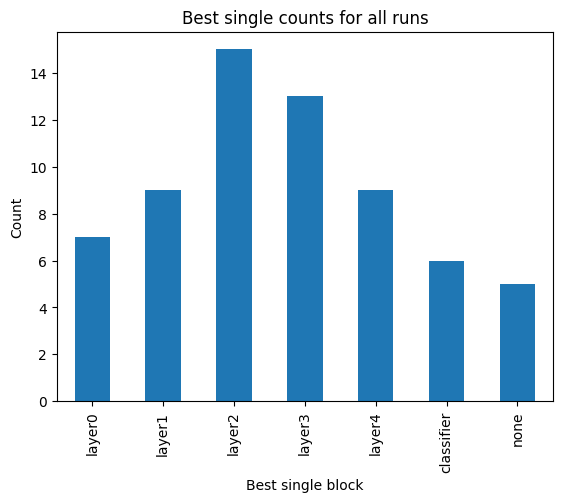

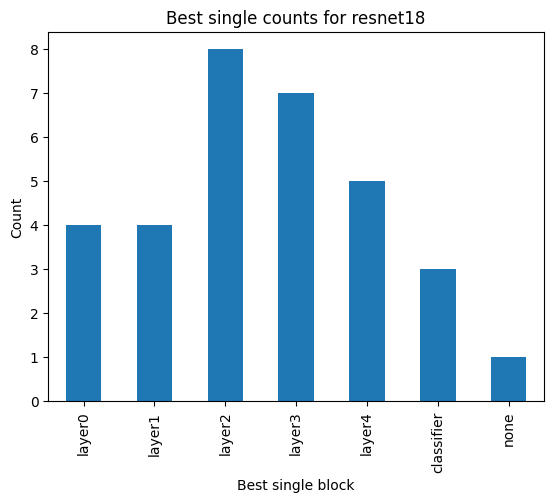

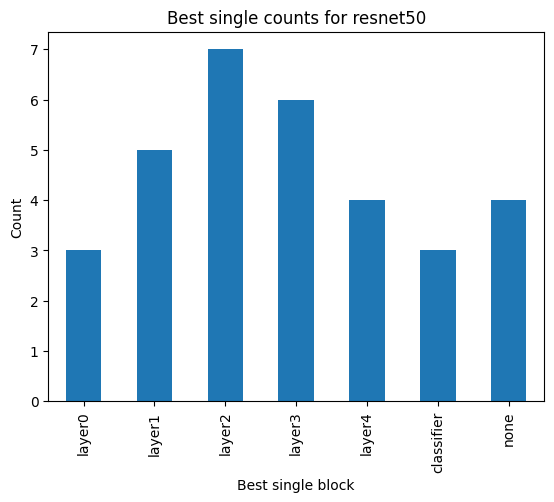

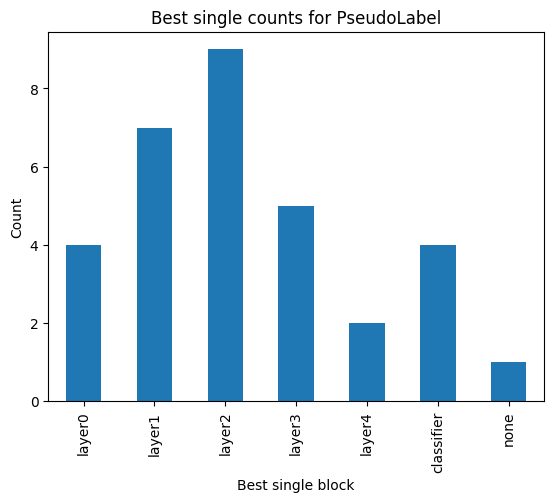

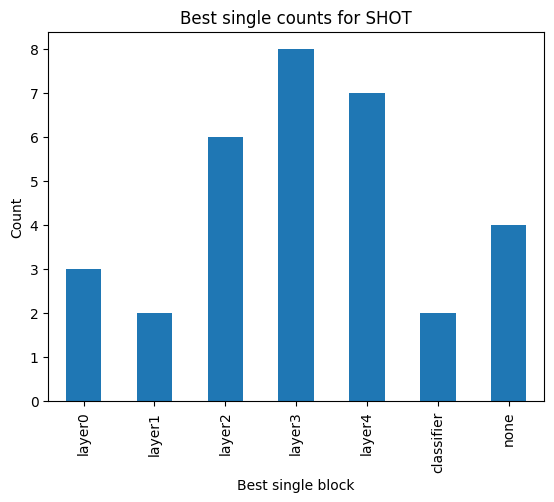

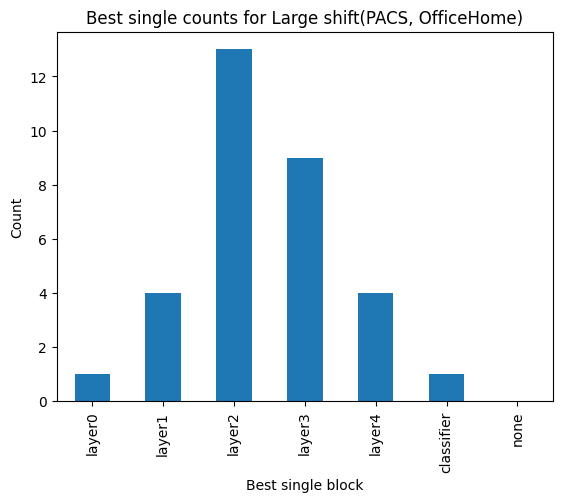

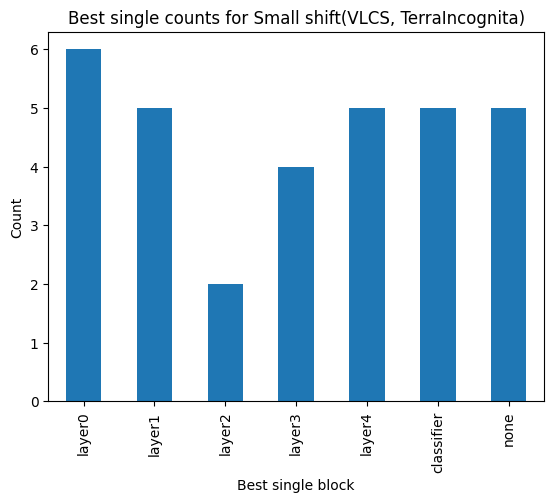

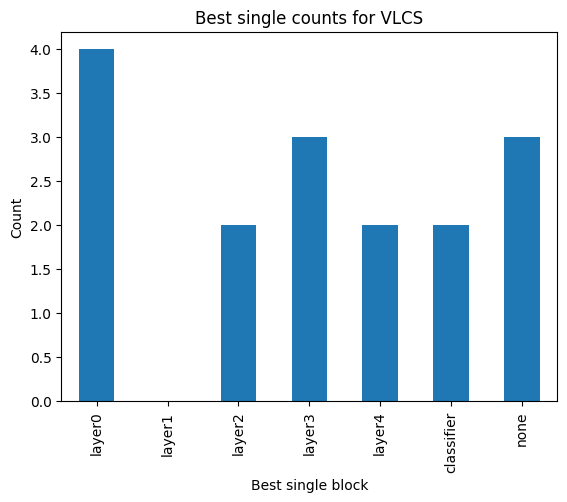

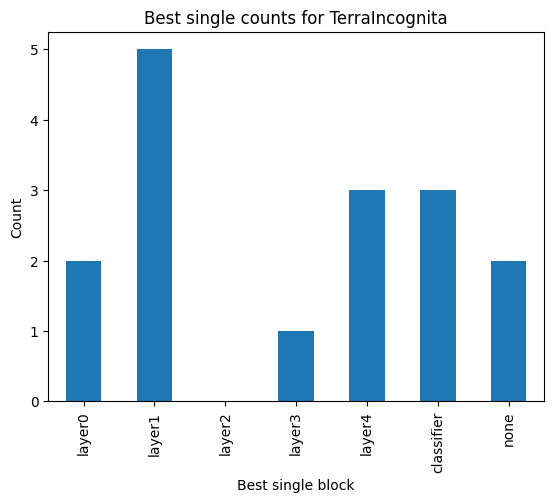

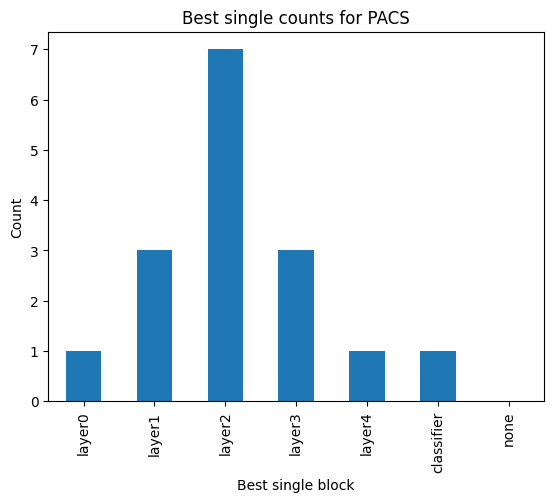

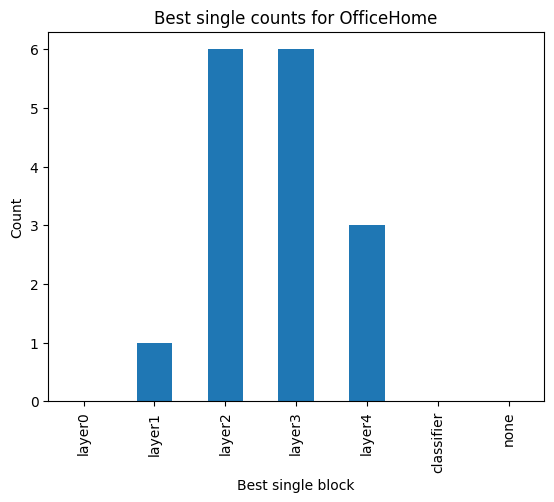

In [14]:
xaxis_order = ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']

plt.figure()
df_best_single_none['find_algo'].value_counts().loc[xaxis_order].plot(kind='bar', title='Best single counts for all runs', xlabel='Best single block', ylabel='Count')

plt.figure()
df_best_single_none[df_best_single_none['backbone'] == 'resnet18-BN']['find_algo'].value_counts().loc[xaxis_order].plot(kind='bar', title='Best single counts for resnet18', xlabel='Best single block', ylabel='Count')
plt.figure()
df_best_single_none[df_best_single_none['backbone'] == 'resnet50-BN']['find_algo'].value_counts().loc[xaxis_order].plot(kind='bar', title='Best single counts for resnet50', xlabel='Best single block', ylabel='Count')

plt.figure()
df_best_single_none[df_best_single_none['tta'] == 'PseudoLabel']['find_algo'].value_counts().loc[xaxis_order].plot(kind='bar', title='Best single counts for PseudoLabel', xlabel='Best single block', ylabel='Count')
plt.figure()
df_best_single_none[df_best_single_none['tta'] == 'SHOT']['find_algo'].value_counts().loc[xaxis_order].plot(kind='bar', title='Best single counts for SHOT', xlabel='Best single block', ylabel='Count')

plt.figure()
df_best_single_none[(df_best_single_none['dataset'] == 'PACS') | (df_best_single_none['dataset'] == 'OfficeHome')]['find_algo'].value_counts().append(pd.Series([0], index=['none'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for Large shift(PACS, OfficeHome)', xlabel='Best single block', ylabel='Count')
plt.figure()
df_best_single_none[(df_best_single_none['dataset'] == 'VLCS') | (df_best_single_none['dataset'] == 'TerraIncognita')]['find_algo'].value_counts().loc[xaxis_order].plot(kind='bar', title='Best single counts for Small shift(VLCS, TerraIncognita)', xlabel='Best single block', ylabel='Count')

plt.figure()
df_best_single_none[df_best_single_none['dataset'] == 'VLCS']['find_algo'].value_counts().append(pd.Series([0], index=['layer1'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for VLCS', xlabel='Best single block', ylabel='Count')
plt.figure()
df_best_single_none[df_best_single_none['dataset'] == 'TerraIncognita']['find_algo'].value_counts().append(pd.Series([0], index=['layer2'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for TerraIncognita', xlabel='Best single block', ylabel='Count')

plt.figure()
df_best_single_none[df_best_single_none['dataset'] == 'PACS']['find_algo'].value_counts().append(pd.Series([0], index=['none'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for PACS', xlabel='Best single block', ylabel='Count')
plt.figure()
df_best_single_none[df_best_single_none['dataset'] == 'OfficeHome']['find_algo'].value_counts().append(pd.Series([0], index=['none'])).append(pd.Series([0], index=['layer0'])).append(pd.Series([0], index=['classifier'])).loc[xaxis_order].plot(kind='bar', title='Best single counts for OfficeHome', xlabel='Best single block', ylabel='Count')

Report average tta_acc in all setups

In [15]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_single.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/2436072159.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_single.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   63.266480  84.325063      48.753207  77.080300   67.722479   
SHOT          63.544315  85.343502      48.116903  77.068172   68.207921   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  87.901920      52.525775  79.314925  
SHOT         88.008613      50.018238  78.003931

In [16]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_single_none.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/3823200683.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_single_none.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   63.266480  84.325063      48.753207  77.080300   67.722479   
SHOT          63.544315  85.343502      48.116903  77.068172   68.207921   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  87.901920      52.578888  79.314925  
SHOT         88.008613      50.018238  78.003931

In [17]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_powerset.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/485214219.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_powerset.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   63.378108  84.988125      49.693026  77.145356   67.772618   
SHOT          63.771719  85.782409      48.288271  77.109297   68.484289   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  88.427378      53.910288  79.533721  
SHOT         88.513338      50.070966  78.003931

How much does including 'none' in layer selection improve perf?

In [18]:
df_best_single_none.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose() - df_best_single.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/3747803604.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_single_none.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose() - df_best_single.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()
/tmp/ipykernel_3099996/3747803604.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_single_none.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose() - df_best_single.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                          resnet50-BN       \
dataset      OfficeHome PACS TerraIncognita VLCS  OfficeHome PACS   
tta                                                                 
PseudoLabel         0.0  0.0            0.0  0.0         0.0  0.0   
SHOT                0.0  0.0            0.0  0.0         0.0  0.0   

backbone                         
dataset     TerraIncognita VLCS  
tta                              
PseudoLabel       0.053112  0.0  
SHOT              0.000000  0.0

In [19]:
df_best_single_none[list(df_best_single_none['find_algo'] == 'none')][['dataset', 'test_env', 'backbone', 'tta', 'find_algo', 'tta_acc']]

,dataset,test_env,backbone,tta,find_algo,tta_acc
1408,VLCS,3,resnet18-BN,SHOT,none,74.601999
1920,VLCS,3,resnet50-BN,SHOT,none,72.824880
1792,VLCS,1,resnet50-BN,SHOT,none,68.094118
2944,TerraIncognita,1,resnet50-BN,SHOT,none,46.681217
2624,TerraIncognita,3,resnet50-BN,PseudoLabel,none,41.342681


In [20]:
df_best_single[list(df_best_single_none['find_algo'] == 'none')][['dataset', 'test_env', 'backbone', 'tta', 'find_algo', 'tta_acc']]

,dataset,test_env,backbone,tta,find_algo,tta_acc
1409,VLCS,3,resnet18-BN,SHOT,classifier,74.601999
1921,VLCS,3,resnet50-BN,SHOT,classifier,72.824880
1793,VLCS,1,resnet50-BN,SHOT,classifier,68.094118
2945,TerraIncognita,1,resnet50-BN,SHOT,classifier,46.681217
2625,TerraIncognita,3,resnet50-BN,PseudoLabel,classifier,41.130232


Report 2nd/3rd best single and best powerset tta_acc

In [21]:
df_best_single_second = pd.DataFrame([df_group.sort_values(by=['tta_acc'], ascending=False).iloc[1].to_dict() for gname, df_group in df_best_hp[flag_single].groupby(['backbone', 'dataset', 'test_env', 'tta'])])
df_best_single_third = pd.DataFrame([df_group.sort_values(by=['tta_acc'], ascending=False).iloc[2].to_dict() for gname, df_group in df_best_hp[flag_single].groupby(['backbone', 'dataset', 'test_env', 'tta'])])

df_best_powerset_second = pd.DataFrame([df_group.sort_values(by=['tta_acc'], ascending=False).iloc[1].to_dict() for gname, df_group in df_best_hp.groupby(['backbone', 'dataset', 'test_env', 'tta'])])
df_best_powerset_third = pd.DataFrame([df_group.sort_values(by=['tta_acc'], ascending=False).iloc[2].to_dict() for gname, df_group in df_best_hp.groupby(['backbone', 'dataset', 'test_env', 'tta'])])

In [22]:
best_row_2 = df_best_single_second.sample()

dataset = best_row_2['dataset'].values[0]
test_env = best_row_2['test_env'].values[0]
backbone = best_row_2['backbone'].values[0]
tta = best_row_2['tta'].values[0]

best_row_2

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
15,10.0,0.9,False,layer0,Trainsubset,1,Block,0.784033,True,False,...,78.403308,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1


In [23]:
df_best_hp[df_best_hp['dataset'] == dataset][df_best_hp['test_env'] == test_env][df_best_hp['backbone'] == backbone][df_best_hp['tta'] == tta].sort_values(by=[target_col], ascending=False)[flag_single]

/tmp/ipykernel_3099996/3768938610.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_best_hp[df_best_hp['dataset'] == dataset][df_best_hp['test_env'] == test_env][df_best_hp['backbone'] == backbone][df_best_hp['tta'] == tta].sort_values(by=[target_col], ascending=False)[flag_single]


,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
448,0.1,0.9,False,layer2,Trainsubset,3,Block,0.801209,False,False,...,80.120865,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1
458,10.0,0.9,False,layer0,Trainsubset,1,Block,0.784033,True,False,...,78.403308,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1
461,0.1,0.9,False,layer1,Trainsubset,3,Block,0.783079,False,True,...,78.307888,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1
476,0.1,0.9,False,layer3,Trainsubset,1,Block,0.771947,False,False,...,77.194656,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1
508,0.1,0.9,False,layer4,Trainsubset,1,Block,0.743003,False,False,...,74.300254,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1
510,10.0,0.9,False,classifier,Trainsubset,1,Block,0.721056,False,False,...,72.105598,0,PACS,3,100,resnet18-BN,ERM,SHOT,Man,0.1


In [24]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_single_second.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/542158219.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_single_second.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   62.989614  83.751279      45.161939  76.386871   67.472273   
SHOT          63.362117  84.750576      42.380313  76.915313   67.890097   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  86.634602      51.600265  78.332792  
SHOT         87.519964      47.585335  77.720692

In [25]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_single_third.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/169987392.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_single_third.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   62.726252  83.341242      41.627530  75.709204   67.053325   
SHOT          63.086765  84.477678      41.630884  76.147821   67.688369   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  84.816057      50.785977  78.073238  
SHOT         86.990490      47.049056  77.203289

In [26]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_powerset_second.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/3731143354.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_powerset_second.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   63.187276  84.884557      48.662619  76.919928   67.709847   
SHOT          63.771719  85.782409      48.288271  77.109297   68.484289   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  88.239104      53.572478  79.417776  
SHOT         88.513338      50.070966  78.003931

In [27]:
# Report average tta_acc for each backbone, dataset and tta combination, transpose it to make it easier to read
df_best_powerset_third.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/221647404.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_powerset_third.groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   63.152912  84.470398      48.285814  76.797095   67.627019   
SHOT          63.724603  85.647440      48.056637  77.043977   68.409020   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  88.193344      52.859086  79.377715  
SHOT         88.259164      48.639909  77.831116

Report tta_acc for constant layer selection algos

In [28]:
df_best_hp[df_best_hp['find_algo'] == 'layer0'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/2487682119.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_hp[df_best_hp['find_algo'] == 'layer0'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   62.697965  82.259078      42.124417  76.320788   66.954789   
SHOT          62.524031  83.483329      41.250294  76.495162   66.934610   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  83.520277      50.504309  77.459421  
SHOT         85.671053      47.513966  77.499173

In [29]:
df_best_hp[df_best_hp['find_algo'] == 'layer1'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/1367845656.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_hp[df_best_hp['find_algo'] == 'layer1'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   62.877986  83.719078      44.185331  75.665034   67.380553   
SHOT          63.200466  84.390732      41.924987  76.609870   67.581137   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  86.642937      51.729307  77.566597  
SHOT         87.340628      46.646312  77.227206

In [30]:
df_best_hp[df_best_hp['find_algo'] == 'layer2'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/932787790.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_hp[df_best_hp['find_algo'] == 'layer2'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   63.081667  84.213067      42.971688  74.481709   67.629249   
SHOT          63.219779  85.234059      39.134698  75.482784   67.702712   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  87.687747      46.237808  77.460241  
SHOT         87.806315      42.985085  76.382032

In [31]:
df_best_hp[df_best_hp['find_algo'] == 'layer3'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/4134210565.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_hp[df_best_hp['find_algo'] == 'layer3'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   62.789473  82.357977      33.908816  73.496677   67.007417   
SHOT          63.239371  84.322139      38.378370  72.552265   67.980164   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  84.709447      47.983685  77.565379  
SHOT         86.745323      42.749580  70.011328

In [32]:
df_best_hp[df_best_hp['find_algo'] == 'layer4'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/3293305521.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_hp[df_best_hp['find_algo'] == 'layer4'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   61.960459  77.265610      29.477217  68.567500   64.649800   
SHOT          63.260925  83.314903      43.811447  72.444329   67.673768   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  81.891336      41.969603  76.485559  
SHOT         85.508013      38.718628  69.161192

In [33]:
df_best_hp[df_best_hp['find_algo'] == 'classifier'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()

/tmp/ipykernel_3099996/964433350.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_best_hp[df_best_hp['find_algo'] == 'classifier'].groupby(['backbone', 'dataset', 'tta']).mean()['tta_acc'].unstack().transpose()


backbone    resnet18-BN                                      resnet50-BN  \
dataset      OfficeHome       PACS TerraIncognita       VLCS  OfficeHome   
tta                                                                        
PseudoLabel   62.719130  82.083675      41.198133  76.519742   67.082851   
SHOT          62.616099  81.174891      40.864739  75.885709   66.943356   

backbone                                          
dataset           PACS TerraIncognita       VLCS  
tta                                               
PseudoLabel  83.976458      51.206753  77.290398  
SHOT         83.020763      48.772075  76.920615

Plot improvement (tta_acc - dg_acc) for each layer, histogram over all runs

In [34]:
df_best_hp['tta_acc>dg'] = [row['tta_acc'] - df_best_hp[(df_best_hp['dataset'] == row['dataset']) & (df_best_hp['test_env'] == row['test_env']) & (df_best_hp['tta'] == row['tta']) & (df_best_hp['backbone'] == row['backbone']) & (df_best_hp['find_algo'] == 'none')]['tta_acc'].values[0] \
    for idx, row in df_best_hp.iterrows()]

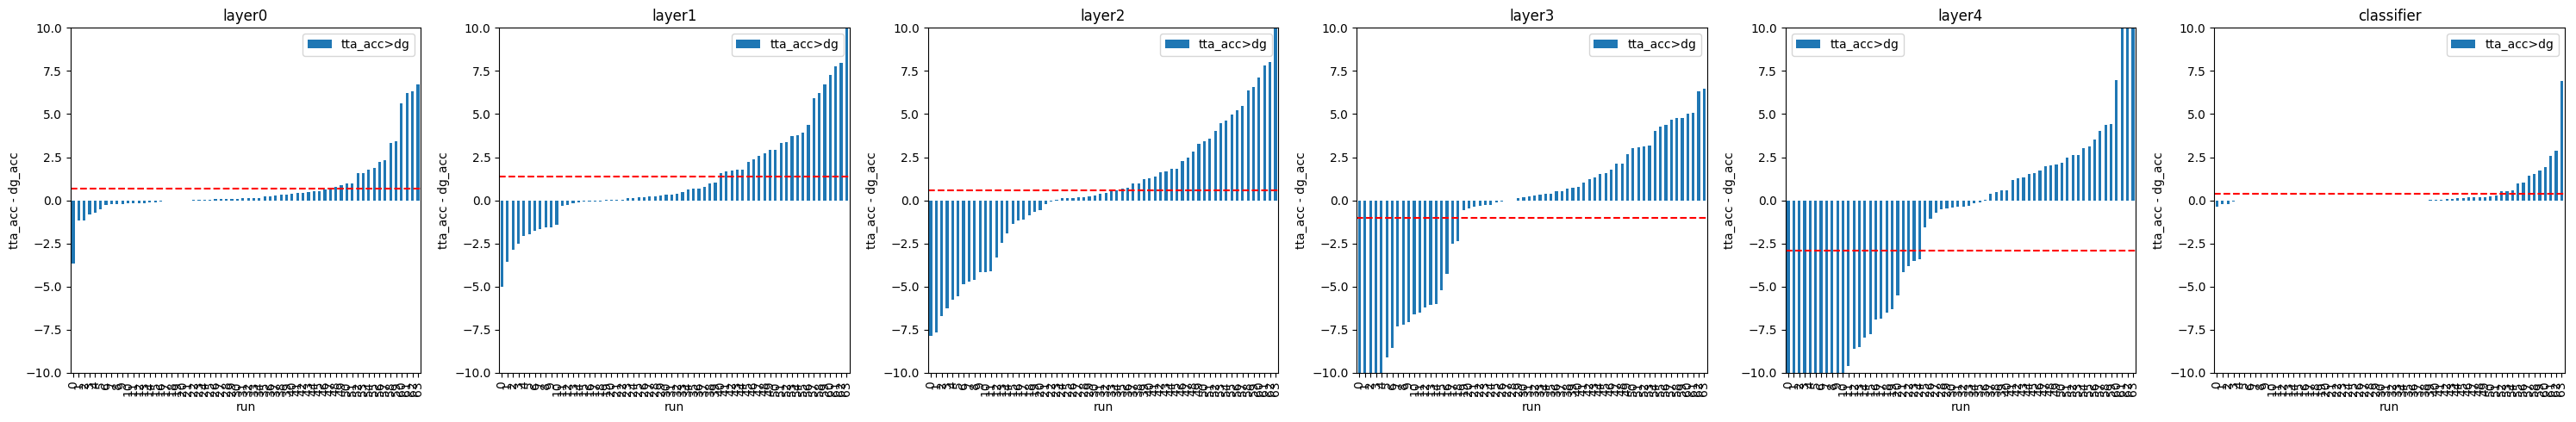

In [35]:
fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
for idx, layer in enumerate(['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier']):
    df_best_hp[(df_best_hp['find_algo'] == layer)][['tta_acc>dg']].sort_values(by=['tta_acc>dg'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title=layer, xlabel='run', ylabel='tta_acc - dg_acc', ax=axes[idx], ylim=(-10, 10))

    # Plot mean tta_acc - dg_acc as dashed horizontal line
    axes[idx].axhline(y=df_best_hp[(df_best_hp['find_algo'] == layer)][['tta_acc>dg']].mean().values[0], color='r', linestyle='--')
plt.tight_layout()

/tmp/ipykernel_3099996/1513848186.py:8: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  axes[idx].axhline(y=df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['dataset'] == dataset)][['dataset', 'tta_acc>dg']].mean().values[0], color='r', linestyle='--')
/tmp/ipykernel_3099996/1513848186.py:8: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  axes[idx].axhline(y=df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['dataset'] == dataset)][['dataset', 'tta_acc>dg']].mean().values[0], color='r', linestyle='--')
/tmp/ipykern

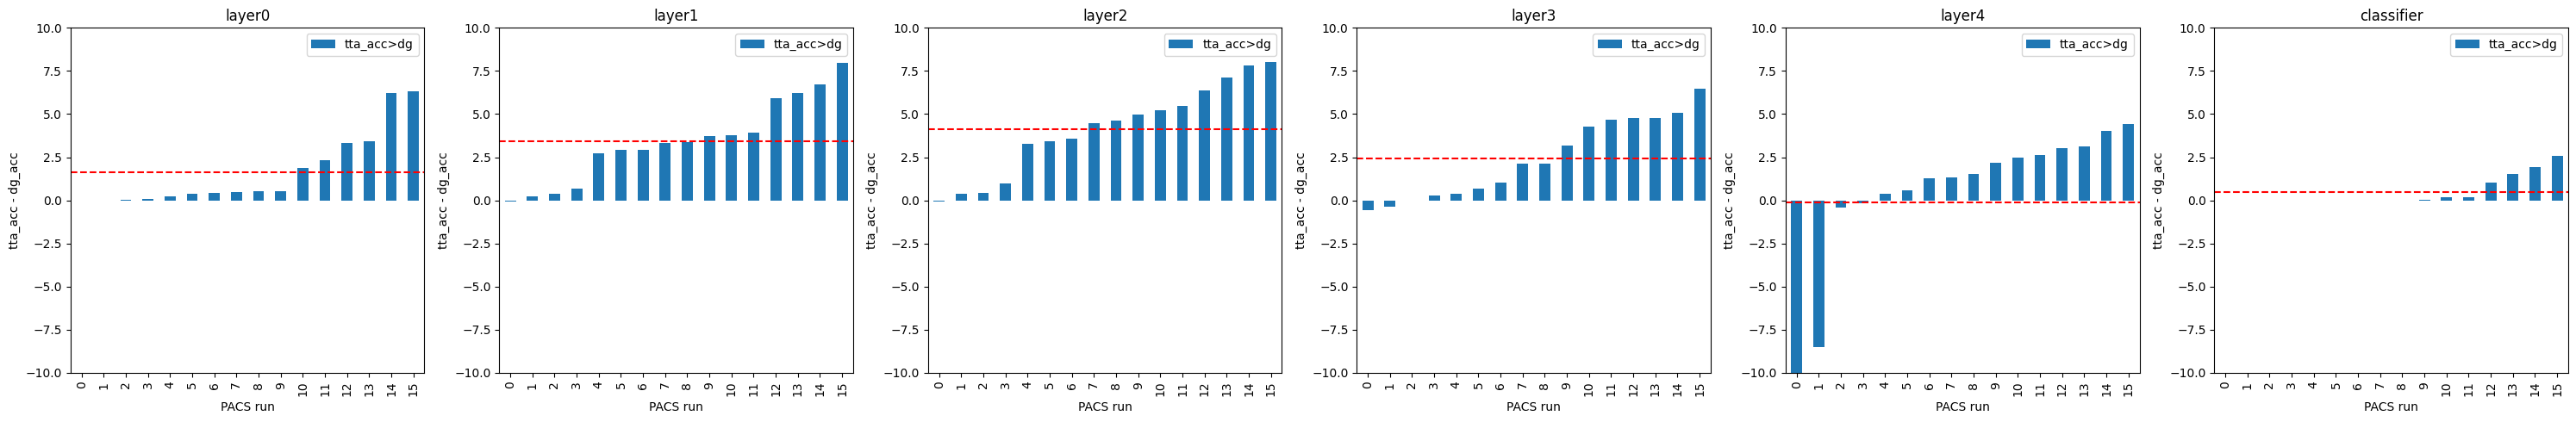

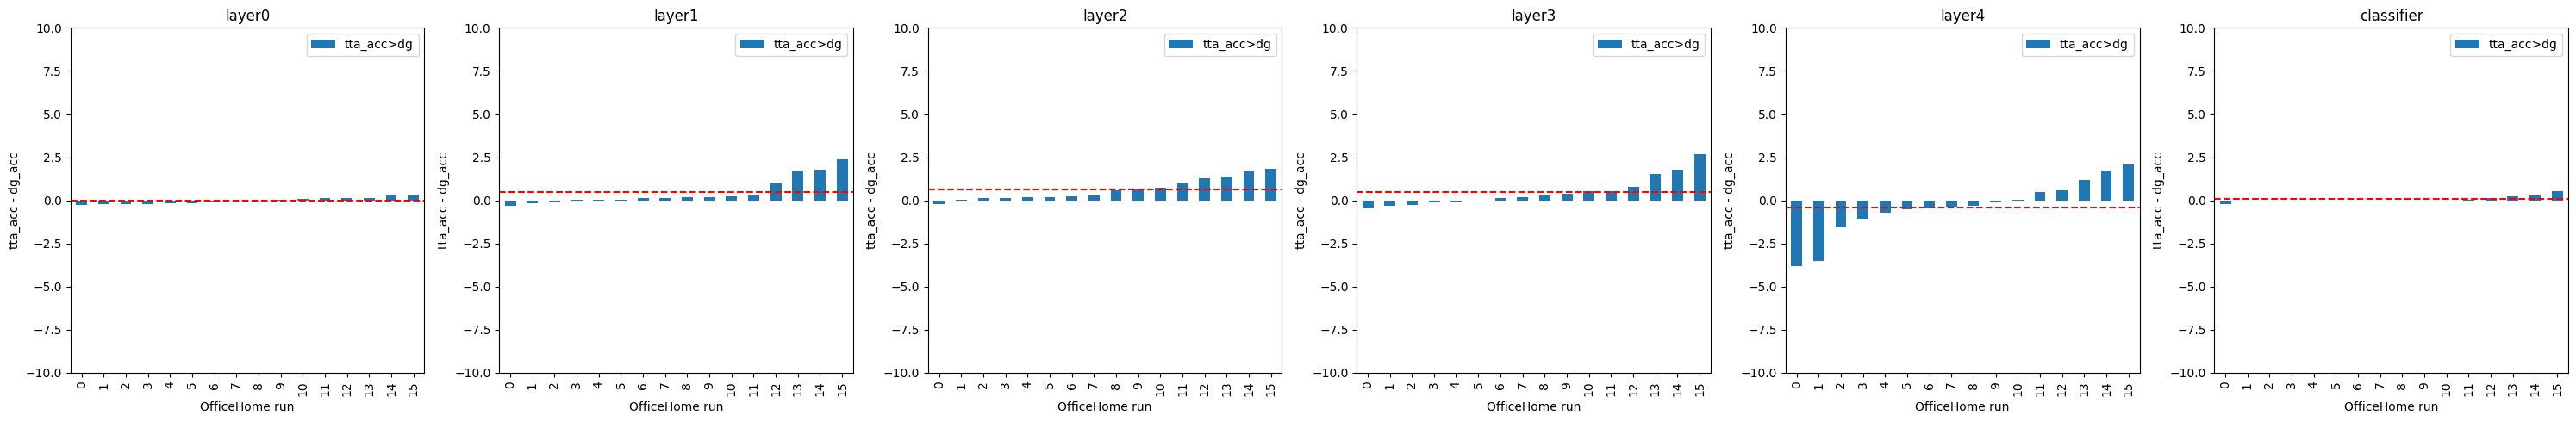

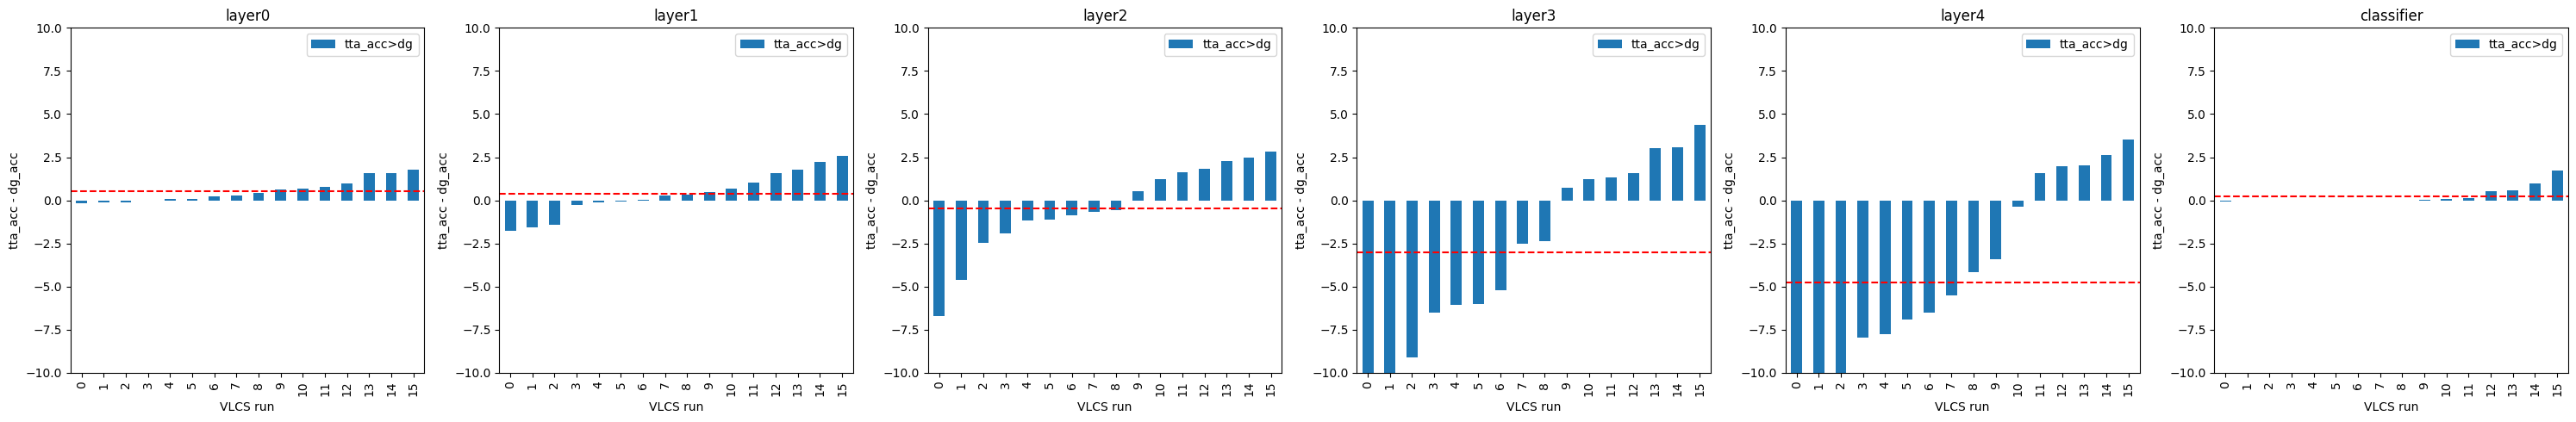

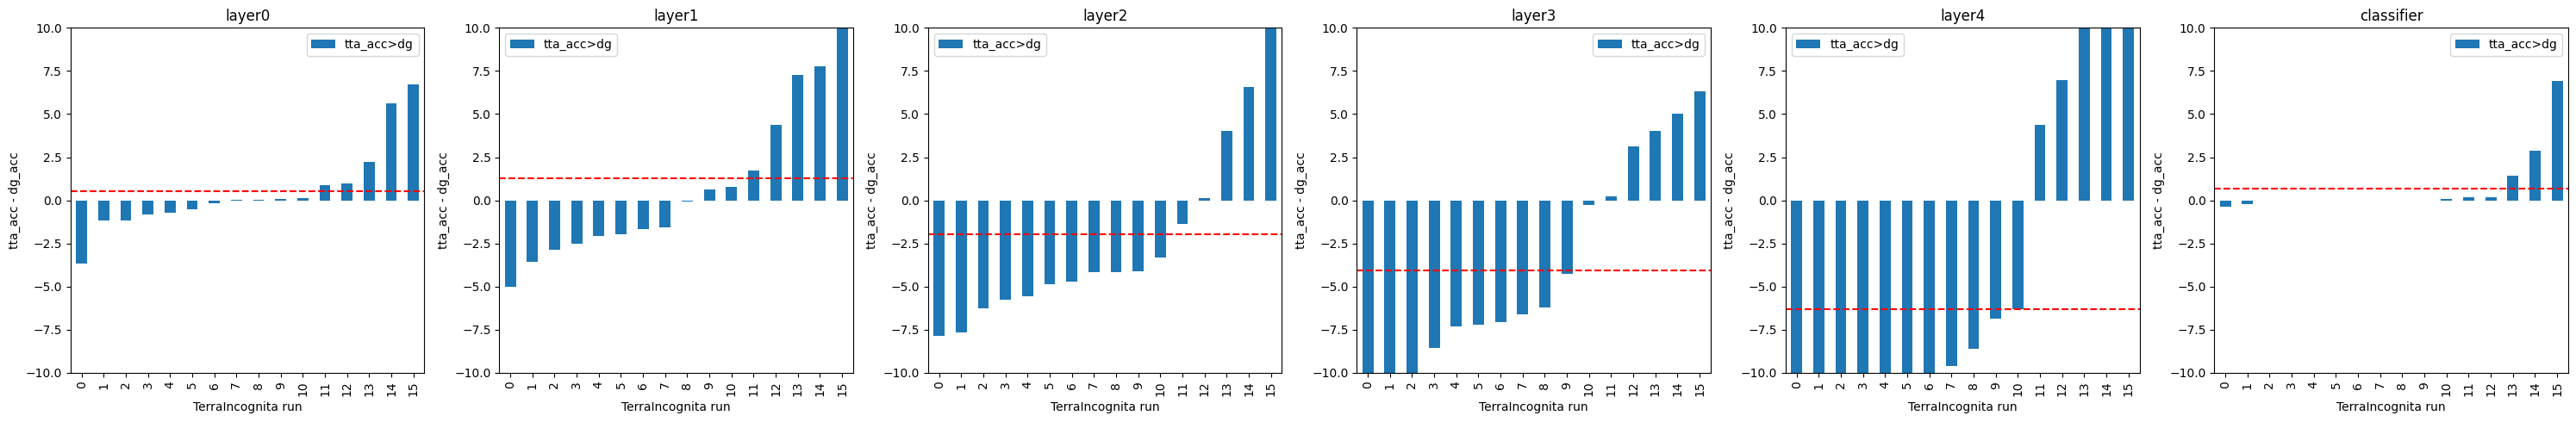

In [36]:
# Plot tta_acc - dg_acc for each dataset into different subplots
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
    for idx, layer in enumerate(['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier']):
        df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['dataset'] == dataset)][['dataset', 'tta_acc>dg']].sort_values(by=['tta_acc>dg'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title=layer, xlabel=dataset+' run', ylabel='tta_acc - dg_acc', ax=axes[idx], ylim=(-10, 10))

        # Plot mean tta_acc - dg_acc as dashed horizontal line
        axes[idx].axhline(y=df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['dataset'] == dataset)][['dataset', 'tta_acc>dg']].mean().values[0], color='r', linestyle='--')
    plt.tight_layout()

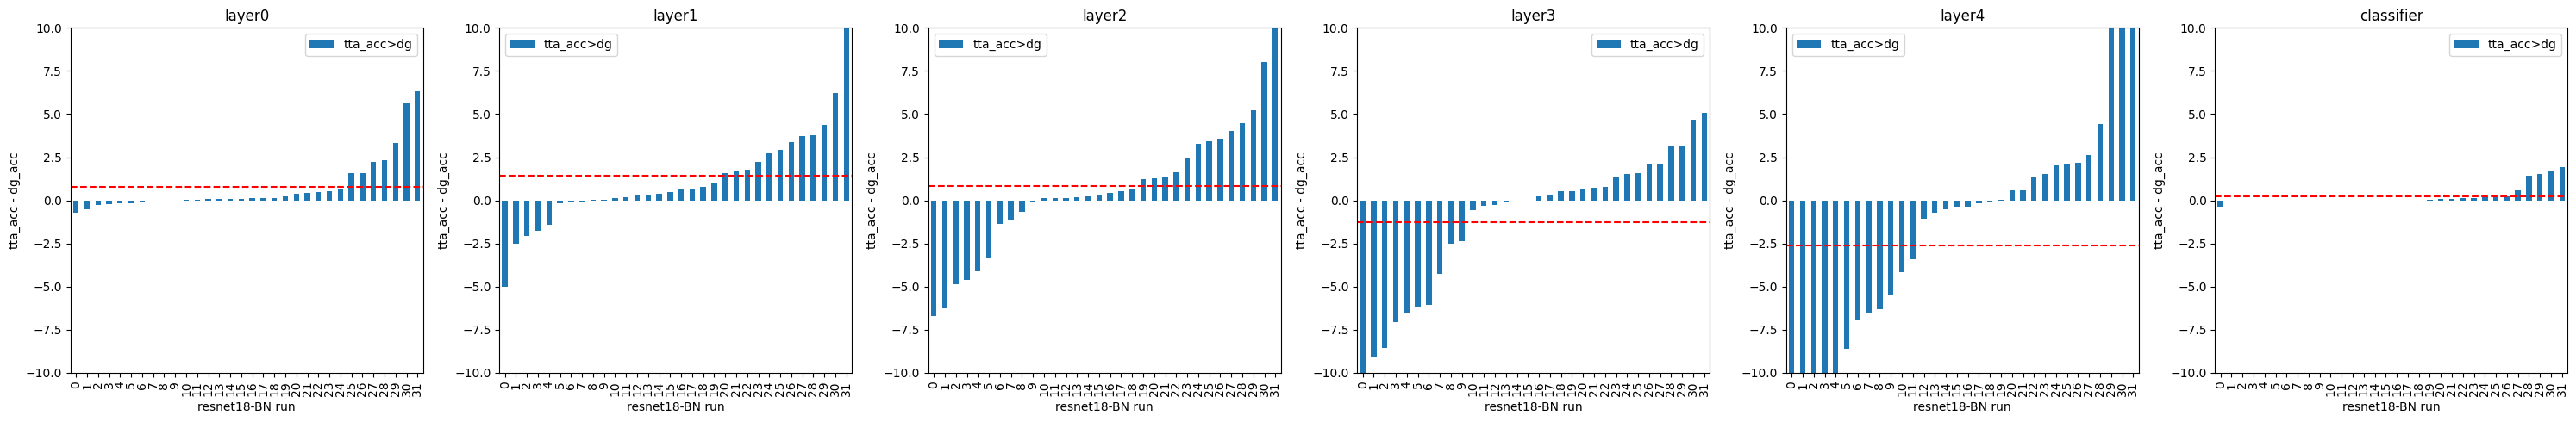

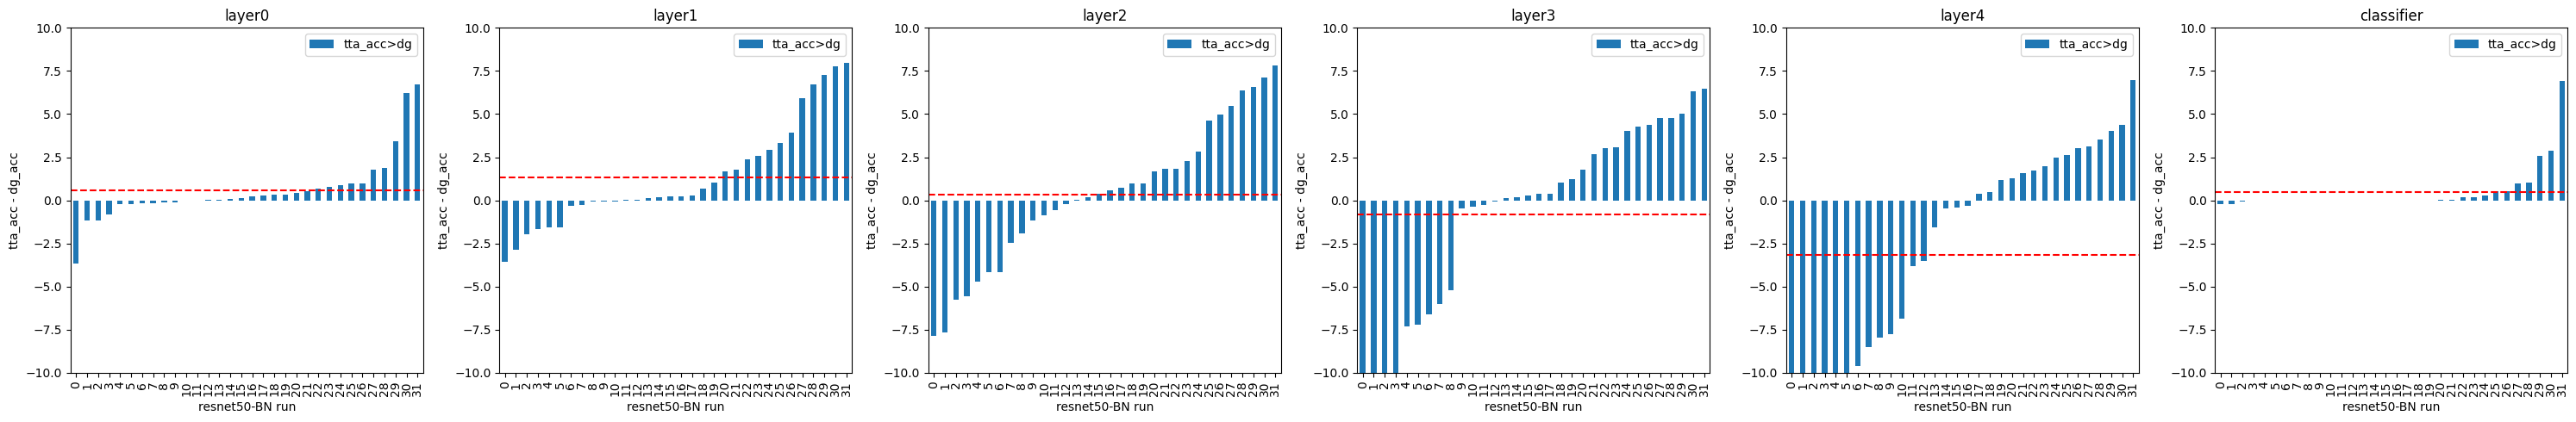

In [37]:
# Plot tta_acc - dg_acc for each backbone into different subplots
for backbone in ['resnet18-BN', 'resnet50-BN']:
    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
    for idx, layer in enumerate(['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier']):
        df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['backbone'] == backbone)][['backbone', 'tta_acc>dg']].sort_values(by=['tta_acc>dg'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title=layer, xlabel=backbone+' run', ylabel='tta_acc - dg_acc', ax=axes[idx], ylim=(-10, 10))
        
        # Plot mean tta_acc - dg_acc as dashed horizontal line
        axes[idx].axhline(y=df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['backbone'] == backbone)][['tta_acc>dg']].mean().values[0], color='r', linestyle='--')
    plt.tight_layout()

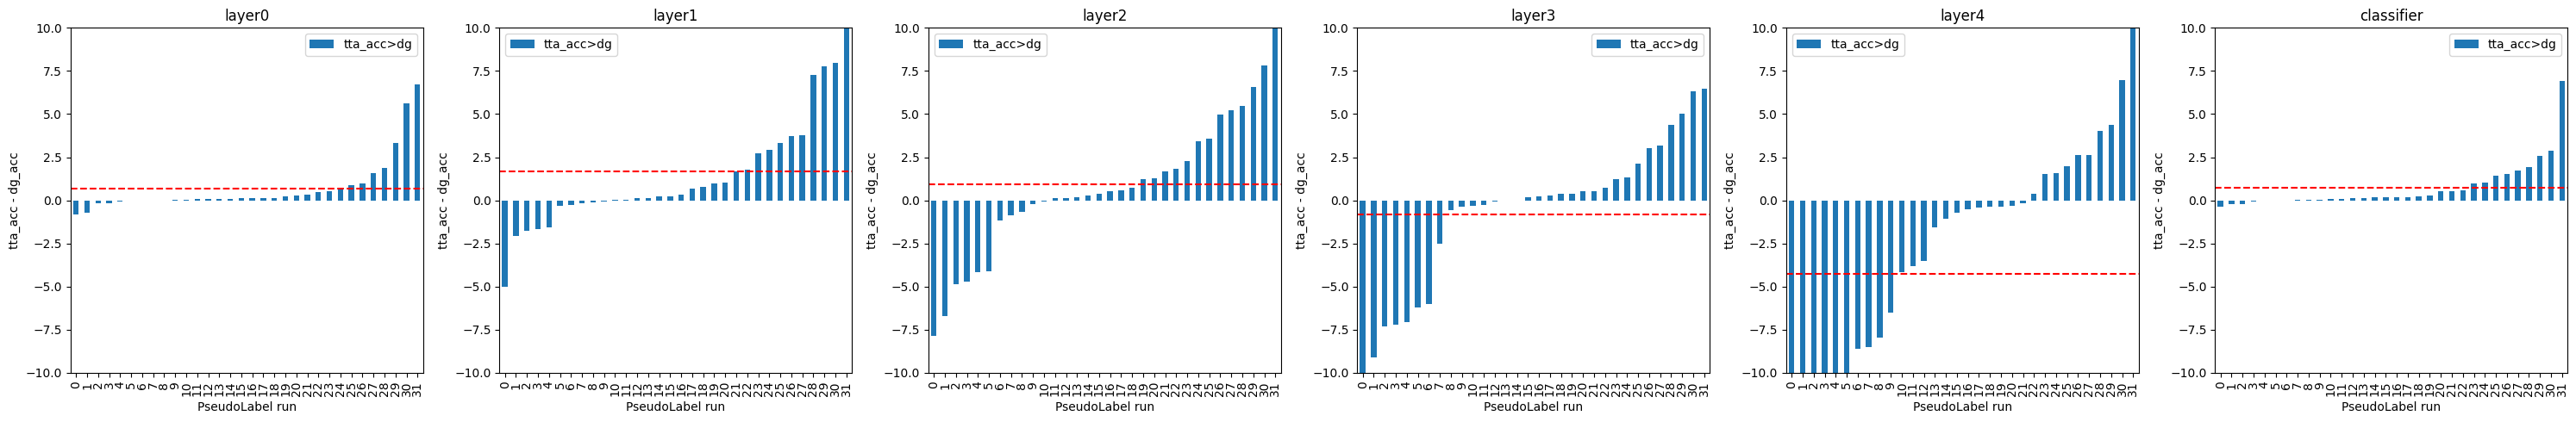

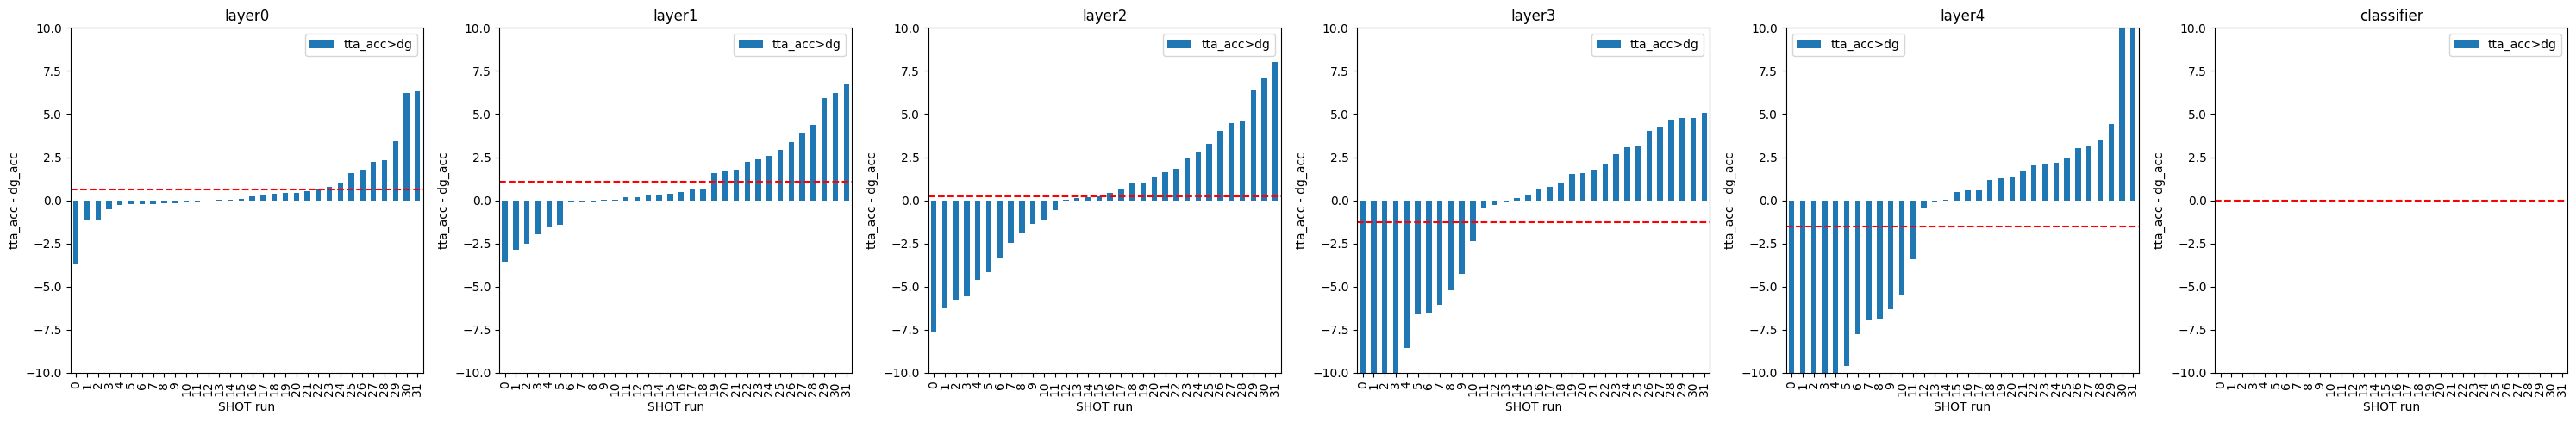

In [38]:
# Plot tta_acc - dg_acc for each tta into different subplots
for tta in ['PseudoLabel', 'SHOT']:
    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
    for idx, layer in enumerate(['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier']):
        df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['tta'] == tta)][['tta', 'tta_acc>dg']].sort_values(by=['tta_acc>dg'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title=layer, xlabel=tta+' run', ylabel='tta_acc - dg_acc', ax=axes[idx], ylim=(-10, 10))

        # Plot mean tta_acc - dg_acc as dashed horizontal line
        axes[idx].axhline(y=df_best_hp[(df_best_hp['find_algo'] == layer) & (df_best_hp['tta'] == tta)]['tta_acc>dg'].mean(), color='r', linestyle='--')
    plt.tight_layout()

Plot best powerset acc - best single acc, histogram for all runs

In [39]:
temp_list = []
for gname, df_group in df_best_hp.groupby(['backbone', 'tta', 'dataset', 'test_env']):
    temp_dict = df_group.iloc[0][['backbone', 'tta', 'dataset', 'test_env']].to_dict()
    temp_dict['powerset>single'] = df_group['tta_acc'].max() - df_group[df_group['count'] == 1]['tta_acc'].max()
    temp_list.append(temp_dict)

df_powerset_gt_single = pd.DataFrame(temp_list)
df_powerset_gt_single

,backbone,tta,dataset,test_env,powerset>single
0,resnet18-BN,PseudoLabel,OfficeHome,0,0.360453
1,resnet18-BN,PseudoLabel,OfficeHome,1,0.000000
2,resnet18-BN,PseudoLabel,OfficeHome,2,0.000000
3,resnet18-BN,PseudoLabel,OfficeHome,3,0.086059
4,resnet18-BN,PseudoLabel,PACS,0,0.732154
...,...,...,...,...,...
59,resnet50-BN,SHOT,TerraIncognita,3,0.000000
60,resnet50-BN,SHOT,VLCS,0,0.000000
61,resnet50-BN,SHOT,VLCS,1,0.000000
62,resnet50-BN,SHOT,VLCS,2,0.000000


<Figure size 640x480 with 0 Axes>

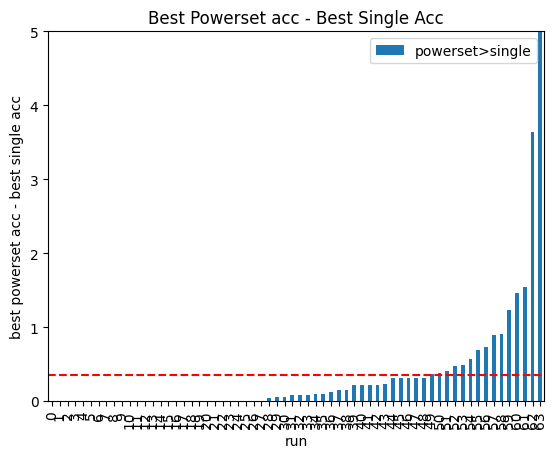

In [40]:
plt.figure()
df_powerset_gt_single[['powerset>single']].sort_values(by=['powerset>single'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title='Best Powerset acc - Best Single Acc', xlabel='run', ylabel='best powerset acc - best single acc', ylim=(0, 5))

# Plot mean powerset acc - best single acc as horizontal line
plt.axhline(y=df_powerset_gt_single[['powerset>single']].mean().values[0], color='r', linestyle='--')

<Figure size 640x480 with 0 Axes>

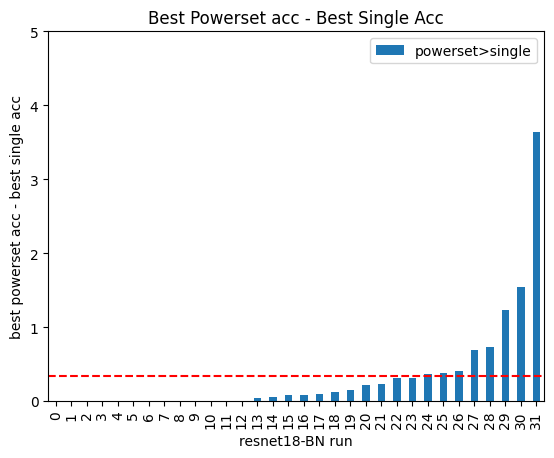

<Figure size 640x480 with 0 Axes>

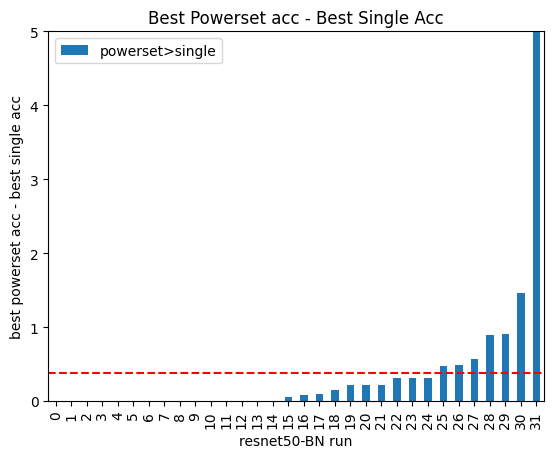

In [41]:
# Plot best powerset acc - best single acc for each backbone
for backbone in ['resnet18-BN', 'resnet50-BN']:
    plt.figure()
    df_powerset_gt_single[df_powerset_gt_single['backbone'] == backbone][['powerset>single']].sort_values(by=['powerset>single'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title='Best Powerset acc - Best Single Acc', xlabel=backbone+' run', ylabel='best powerset acc - best single acc', ylim=(0, 5))

    # Plot mean powerset acc - best single acc as horizontal line
    plt.axhline(y=df_powerset_gt_single[df_powerset_gt_single['backbone'] == backbone]['powerset>single'].mean(), color='r', linestyle='--', label='mean')

<Figure size 640x480 with 0 Axes>

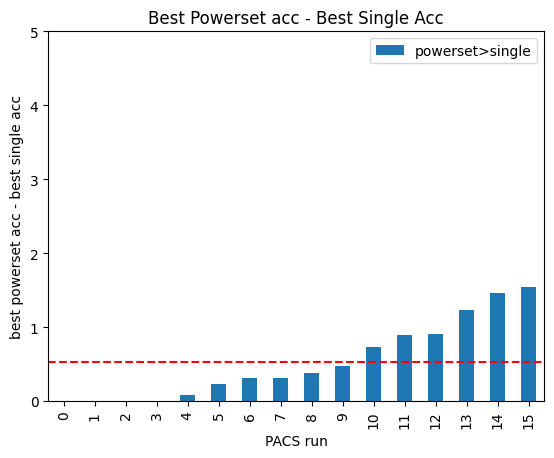

<Figure size 640x480 with 0 Axes>

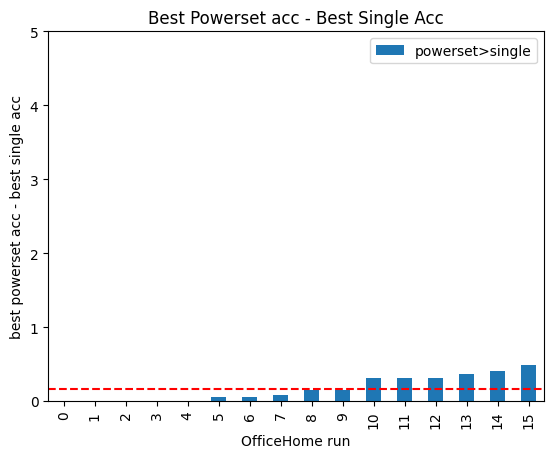

<Figure size 640x480 with 0 Axes>

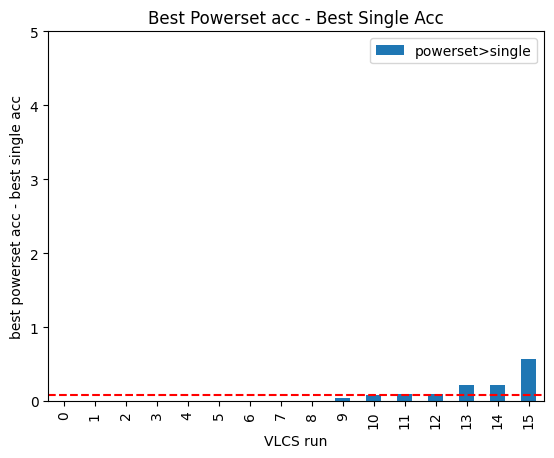

<Figure size 640x480 with 0 Axes>

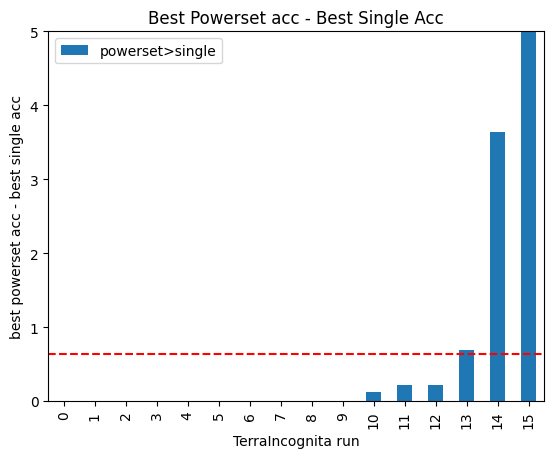

In [42]:
# Plot best powerset acc - best single acc for each dataset
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    plt.figure()
    df_powerset_gt_single[df_powerset_gt_single['dataset'] == dataset][['powerset>single']].sort_values(by=['powerset>single'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title='Best Powerset acc - Best Single Acc', xlabel=dataset+' run', ylabel='best powerset acc - best single acc', ylim=(0, 5))

    # Plot mean powerset acc - best single acc as horizontal line
    plt.axhline(y=df_powerset_gt_single[df_powerset_gt_single['dataset'] == dataset][['powerset>single']].mean().values[0], color='r', linestyle='--')

<Figure size 640x480 with 0 Axes>

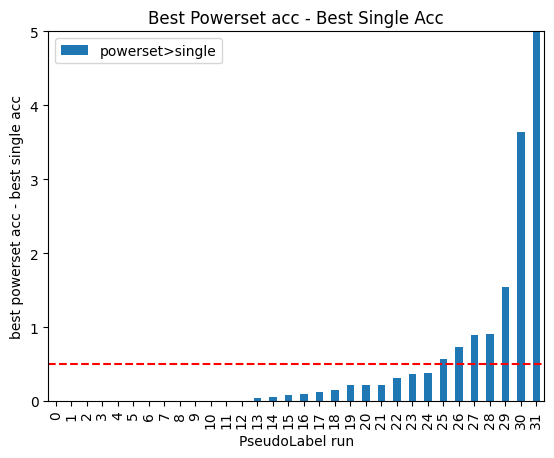

<Figure size 640x480 with 0 Axes>

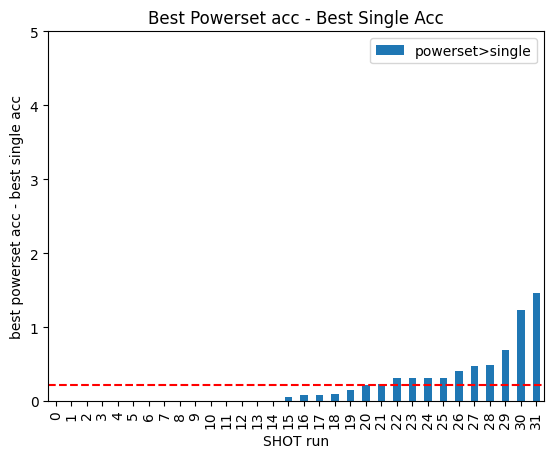

In [43]:
# Plot best powerset acc - best single acc for each tta
for tta in ['PseudoLabel', 'SHOT']:
    plt.figure()
    df_powerset_gt_single[df_powerset_gt_single['tta'] == tta][['powerset>single']].sort_values(by=['powerset>single'], ascending=True).reset_index().drop(columns=['index']).plot(kind='bar', title='Best Powerset acc - Best Single Acc', xlabel=tta+' run', ylabel='best powerset acc - best single acc', ylim=(0, 5))

    # Plot mean powerset acc - best single acc as horizontal line
    plt.axhline(y=df_powerset_gt_single[df_powerset_gt_single['tta'] == tta][['powerset>single']].mean().values[0], color='r', linestyle='--')

Plot tta_acc for each hyperparameter set, histogram over all runs

In [44]:
df_all_hp['theta'].fillna(0.1, inplace=True)

In [45]:
list(df_all_hp.groupby(['alpha', 'beta', 'gamma', 'theta']))

[((0.1, 0.9, 1, 0.1),
         alpha  beta  cached_loader  \
  0        0.1   0.9          False   
  1        0.1   0.9          False   
  2        0.1   0.9          False   
  3        0.1   0.9          False   
  4        0.1   0.9          False   
  ...      ...   ...            ...   
  24251    0.1   0.9          False   
  24252    0.1   0.9          False   
  24253    0.1   0.9          False   
  24254    0.1   0.9          False   
  24255    0.1   0.9          False   
  
                                             find_algo     fix_algo  gamma  \
  0                                               none  Trainsubset      1   
  1                                             layer0  Trainsubset      1   
  2                                             layer1  Trainsubset      1   
  3                                             layer2  Trainsubset      1   
  4                                             layer3  Trainsubset      1   
  ...                                  

In [46]:
df_group = list(df_all_hp.groupby(['alpha', 'beta', 'gamma', 'theta']))[0][1]
df_group

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode,theta
0,0.1,0.9,False,none,Trainsubset,1,Block,0.760128,76.012793,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,0.1
1,0.1,0.9,False,layer0,Trainsubset,1,Block,0.758529,75.852878,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,0.1
2,0.1,0.9,False,layer1,Trainsubset,1,Block,0.762260,76.226013,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,0.1
3,0.1,0.9,False,layer2,Trainsubset,1,Block,0.777186,77.718550,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,0.1
4,0.1,0.9,False,layer3,Trainsubset,1,Block,0.781450,78.144989,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man,0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24251,0.1,0.9,False,layer0_layer1_layer2_layer4_classifier,Trainsubset,1,Block,0.625644,62.564367,0,OfficeHome,0,100,resnet50-BN,ERM,SHOT,Man,0.1
24252,0.1,0.9,False,layer0_layer1_layer3_layer4_classifier,Trainsubset,1,Block,0.625644,62.564367,0,OfficeHome,0,100,resnet50-BN,ERM,SHOT,Man,0.1
24253,0.1,0.9,False,layer0_layer2_layer3_layer4_classifier,Trainsubset,1,Block,0.626159,62.615860,0,OfficeHome,0,100,resnet50-BN,ERM,SHOT,Man,0.1
24254,0.1,0.9,False,layer1_layer2_layer3_layer4_classifier,Trainsubset,1,Block,0.625129,62.512873,0,OfficeHome,0,100,resnet50-BN,ERM,SHOT,Man,0.1


/tmp/ipykernel_3099996/4248742953.py:4: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_group.groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel='run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])
/tmp/ipykernel_3099996/4248742953.py:7: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  axes[idx].axhline(y=df_group.groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='--')
/tmp/ipykernel_3099996/4248742953.py:4: FutureWarning: The default va

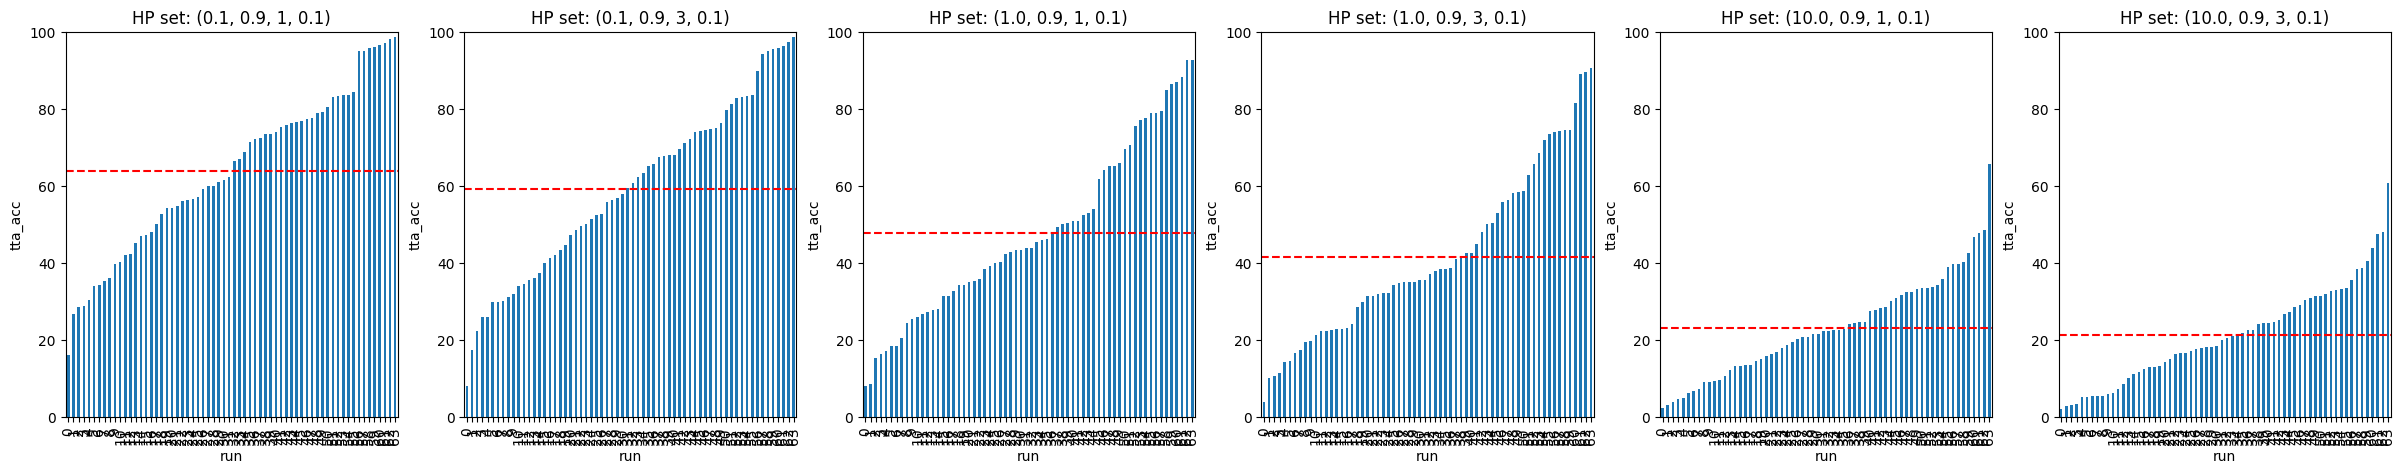

In [47]:
# 
fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
for idx, (gname, df_group) in enumerate(df_all_hp.groupby(['alpha', 'beta', 'gamma', 'theta'])):
    df_group.groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel='run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])

    # Plot mean tta_acc as horizontal line
    axes[idx].axhline(y=df_group.groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='--')

/tmp/ipykernel_3099996/3330944612.py:5: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_group[df_group['dataset'] == dataset].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel=dataset+' run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])
/tmp/ipykernel_3099996/3330944612.py:8: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  axes[idx].axhline(y=df_group[df_group['dataset'] == dataset].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='-

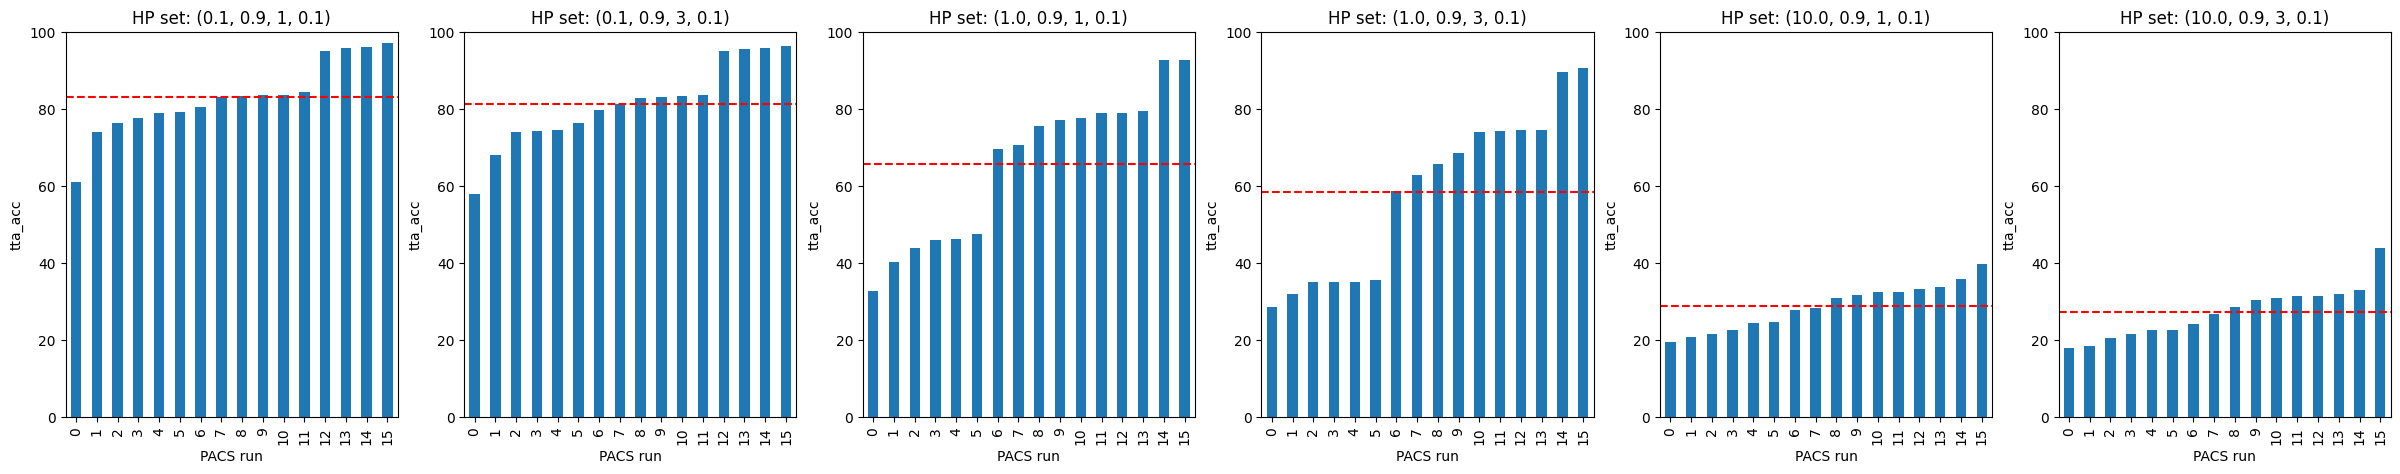

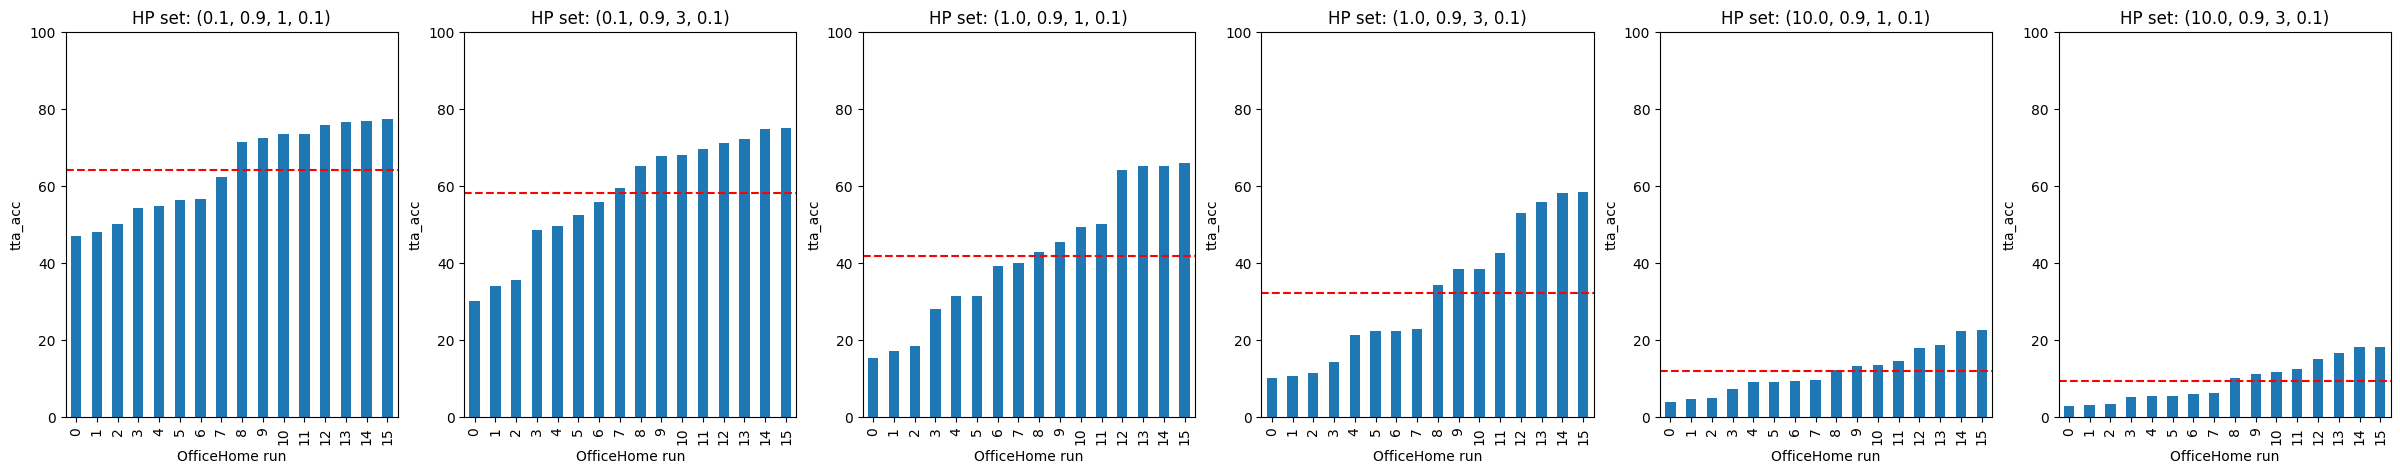

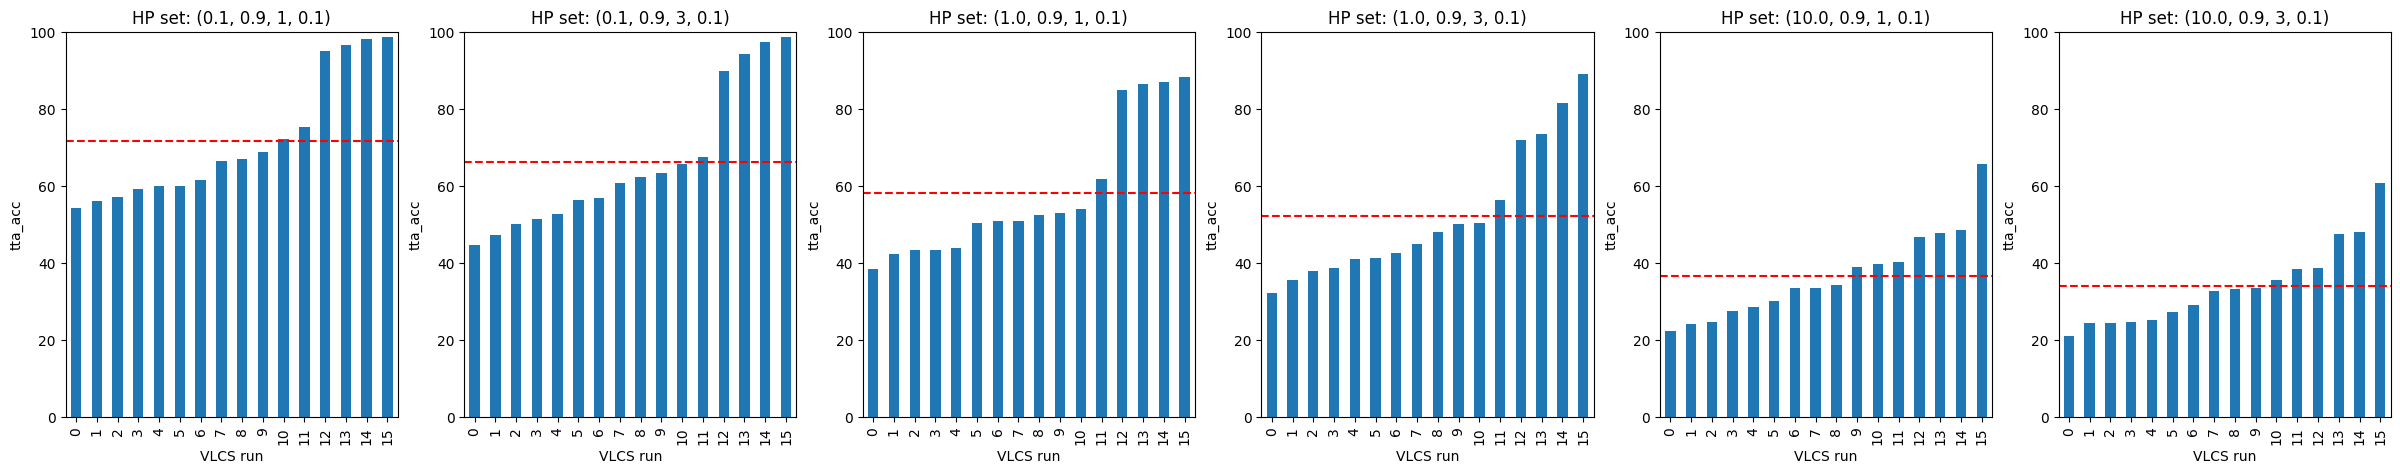

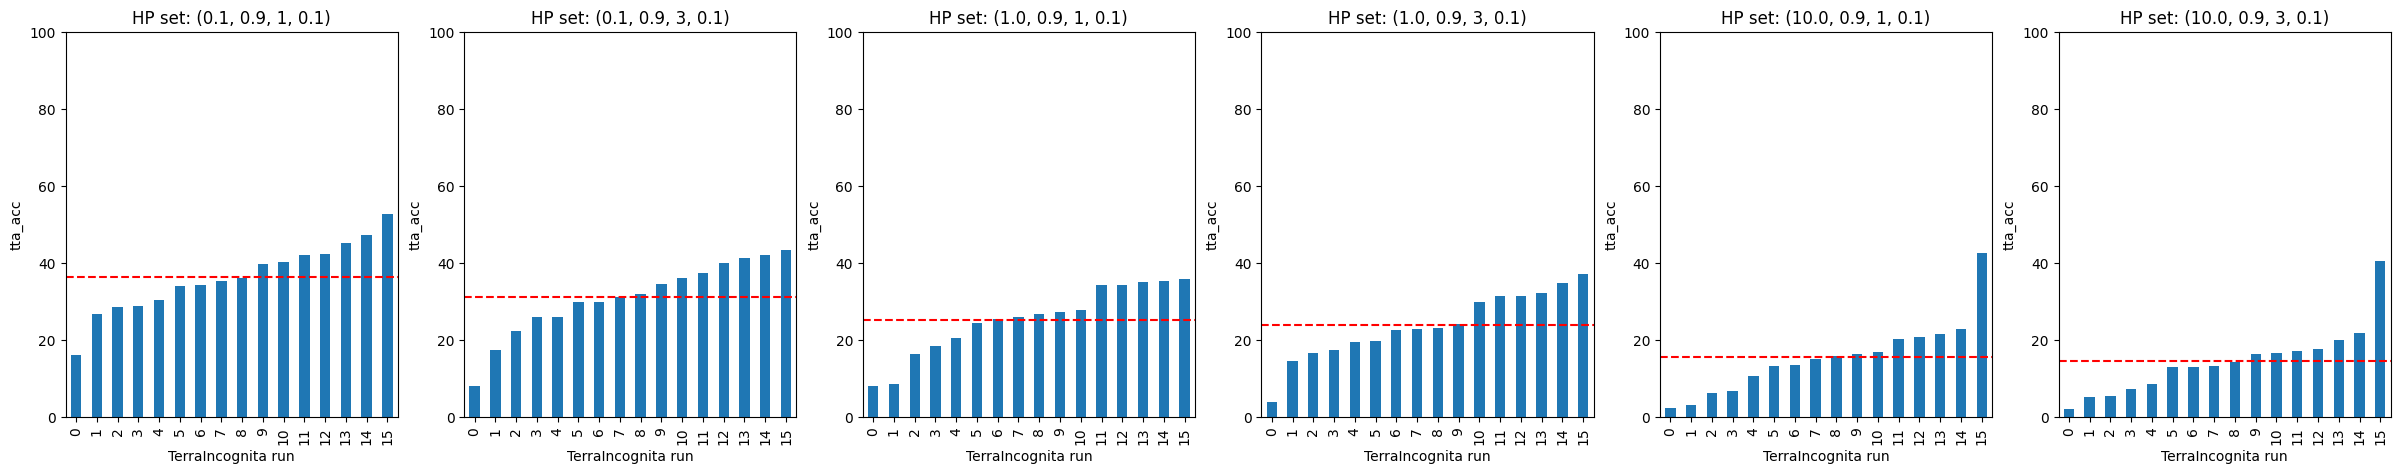

In [48]:
# Plot tta_acc for each dataset into different subplots for each HP set
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
    for idx, (gname, df_group) in enumerate(df_all_hp.groupby(['alpha', 'beta', 'gamma', 'theta'])):
        df_group[df_group['dataset'] == dataset].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel=dataset+' run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])

        # Plot mean tta_acc as horizontal line
        axes[idx].axhline(y=df_group[df_group['dataset'] == dataset].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='--')

/tmp/ipykernel_3099996/1668424461.py:5: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_group[df_group['backbone'] == backbone].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel=backbone+' run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])
/tmp/ipykernel_3099996/1668424461.py:8: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  axes[idx].axhline(y=df_group[df_group['backbone'] == backbone].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linesty

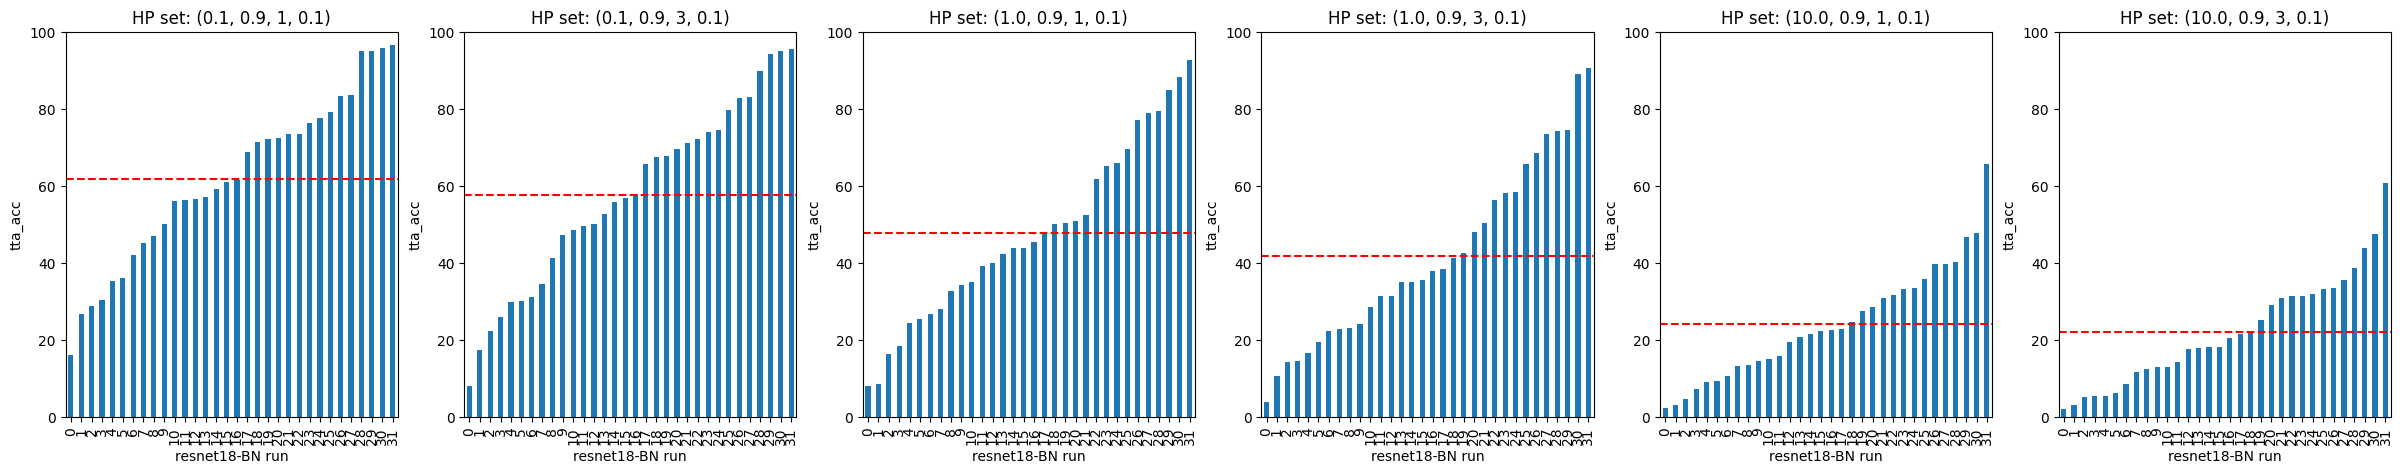

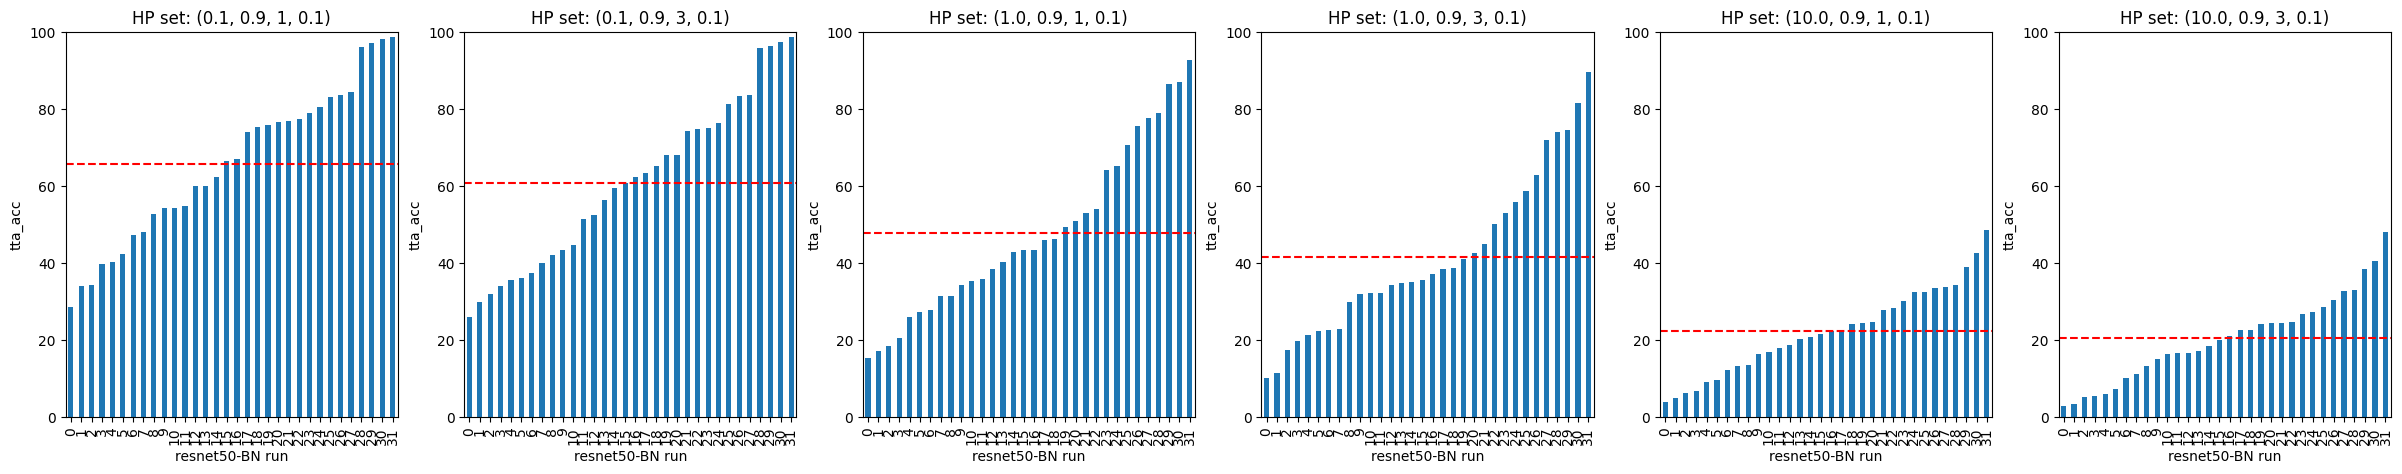

In [49]:
# Plot tta_acc for each backbone into different subplots for each HP set
for backbone in ['resnet18-BN', 'resnet50-BN']:
    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
    for idx, (gname, df_group) in enumerate(df_all_hp.groupby(['alpha', 'beta', 'gamma', 'theta'])):
        df_group[df_group['backbone'] == backbone].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel=backbone+' run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])

        # Plot mean tta_acc as horizontal line
        axes[idx].axhline(y=df_group[df_group['backbone'] == backbone].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='--')

/tmp/ipykernel_3099996/637926460.py:5: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_group[df_group['tta'] == tta].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel=tta+' run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])
/tmp/ipykernel_3099996/637926460.py:8: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  axes[idx].axhline(y=df_group[df_group['tta'] == tta].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='--')
/tmp/ipykernel_309

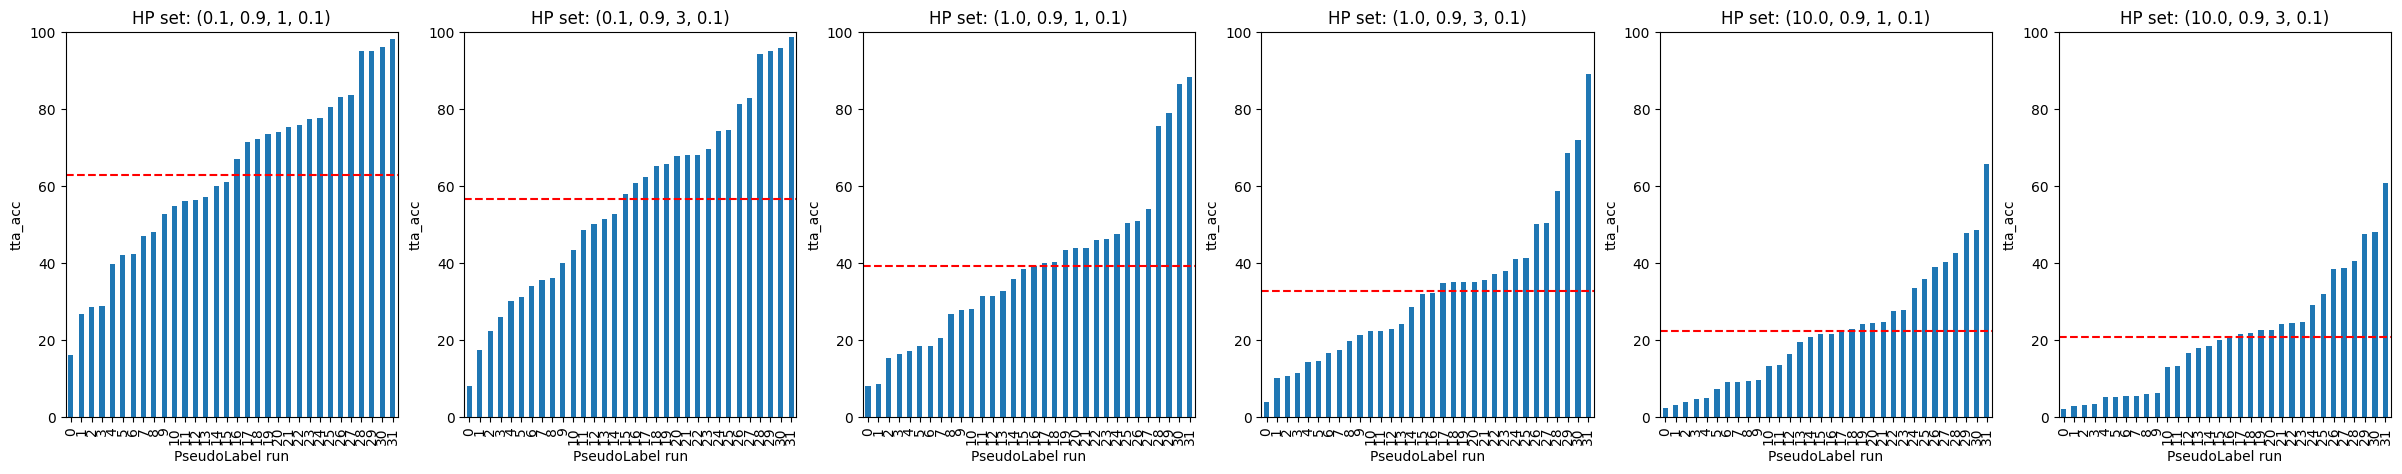

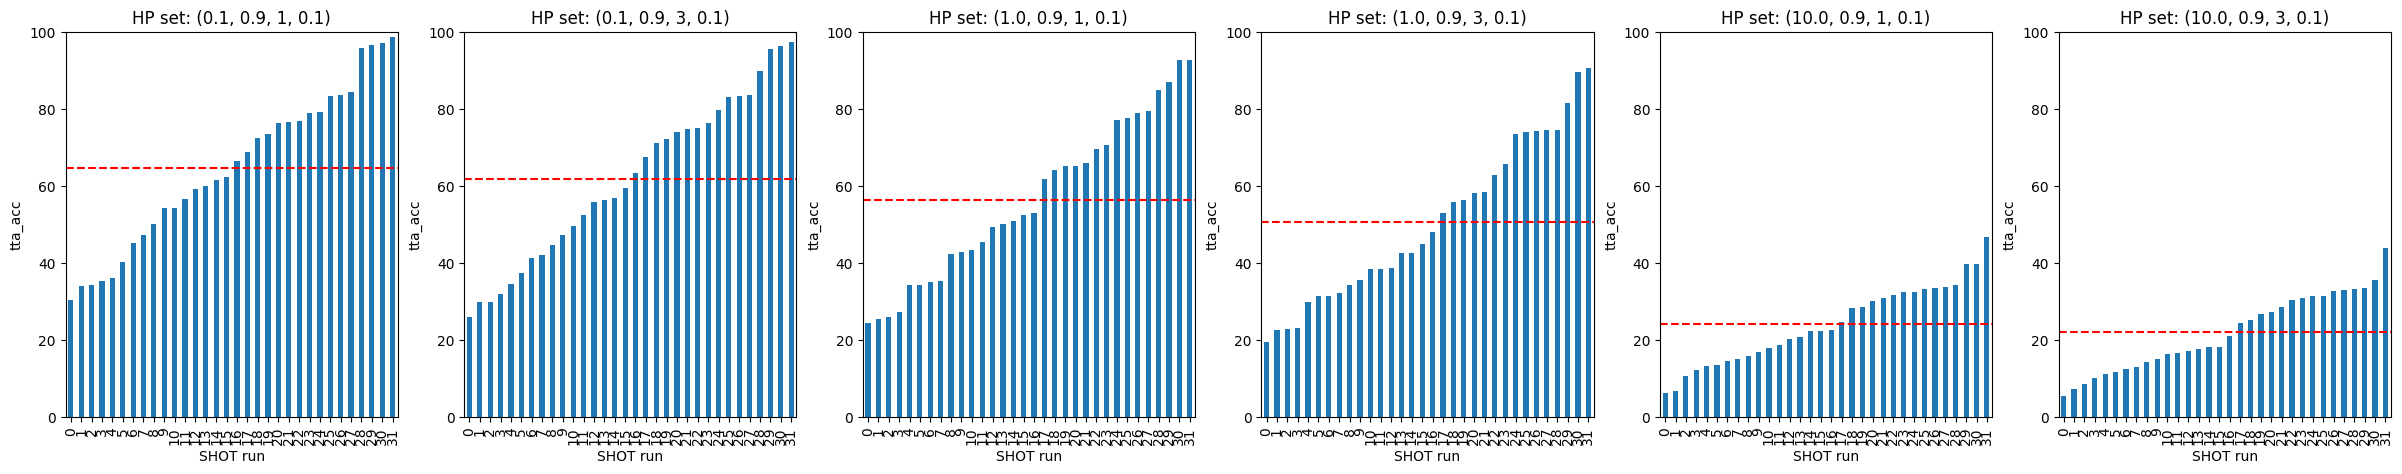

In [50]:
# Plot tta_acc for each tta into different subplots for each HP set
for tta in ['PseudoLabel', 'SHOT']:
    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(30, 5))
    for idx, (gname, df_group) in enumerate(df_all_hp.groupby(['alpha', 'beta', 'gamma', 'theta'])):
        df_group[df_group['tta'] == tta].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].sort_values(ascending=True).reset_index()['tta_acc'].plot(kind='bar', title='HP set: '+str(gname), xlabel=tta+' run', ylabel='tta_acc', ylim=(0, 100), ax=axes[idx])

        # Plot mean tta_acc as horizontal line
        axes[idx].axhline(y=df_group[df_group['tta'] == tta].groupby(['backbone', 'tta', 'dataset', 'test_env']).mean()['tta_acc'].mean(), color='r', linestyle='--')


Plot mean tta_acc, mean over all runs, histogram for all powerset subsets

<Axes: title={'center': 'mean(tta_acc) - mean(dg_acc) for each layer subset'}, xlabel='layer subset for all runs', ylabel='mean(tta_acc) - mean(dg_acc)'>

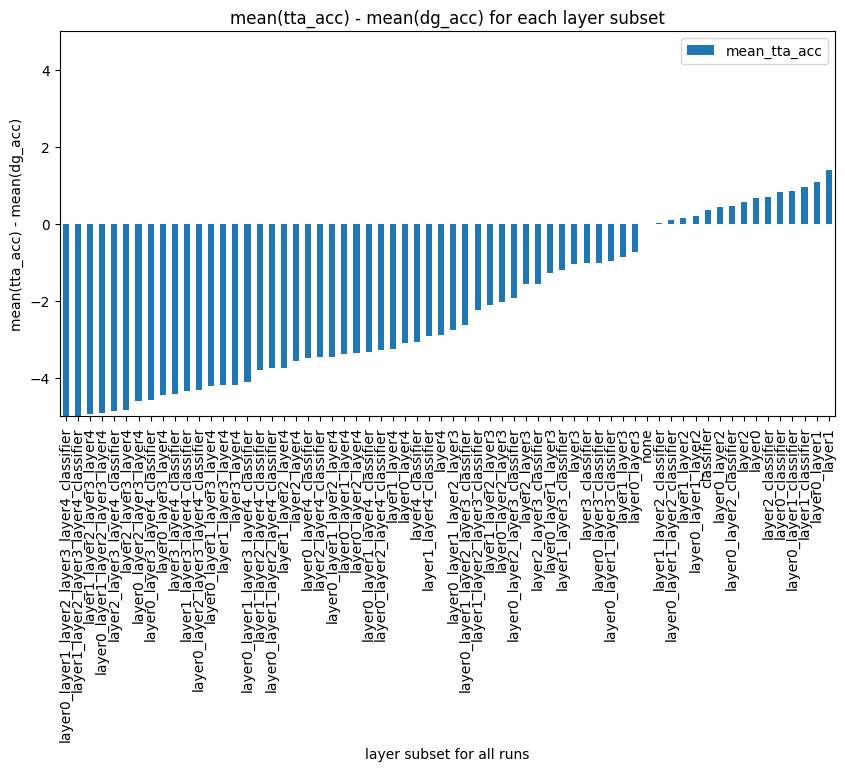

In [51]:
# Plot mean tta_acc for all setups for different layer subsets
temp_list = []
for layer_subset in df_best_hp['find_algo'].unique():
    temp_dict = {}
    temp_dict['layer_subset'] = layer_subset
    temp_dict['mean_tta_acc'] = df_best_hp[df_best_hp['find_algo'] == layer_subset]['tta_acc'].mean()
    temp_list.append(temp_dict)

df_mean_tta_acc = pd.DataFrame(temp_list)
df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
df_mean_tta_acc.sort_values(by=['mean_tta_acc'], ascending=True).set_index('layer_subset').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for all runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))

<Figure size 640x480 with 0 Axes>

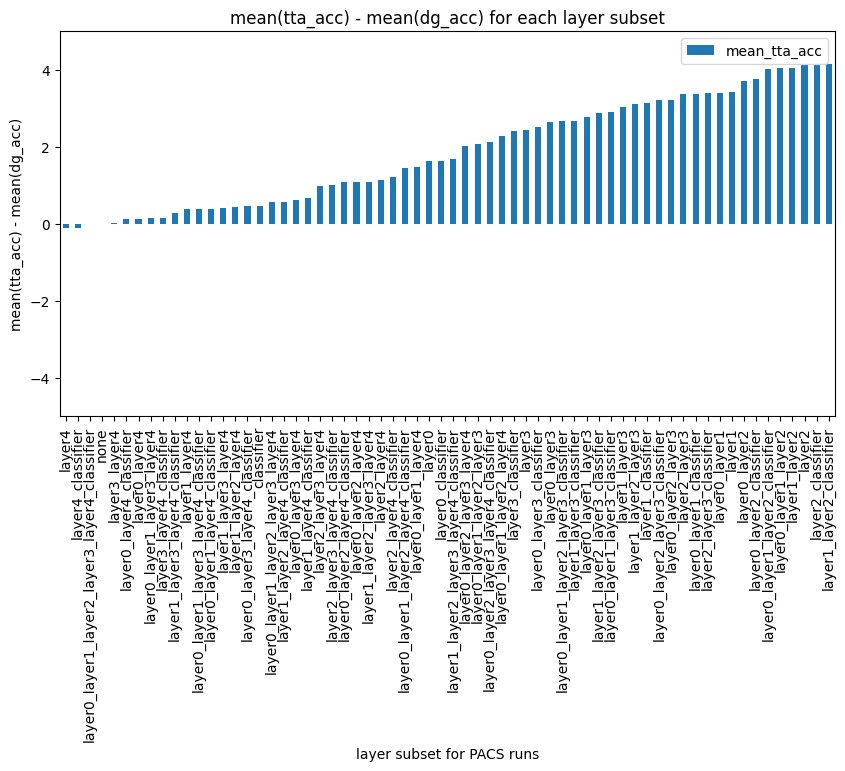

<Figure size 640x480 with 0 Axes>

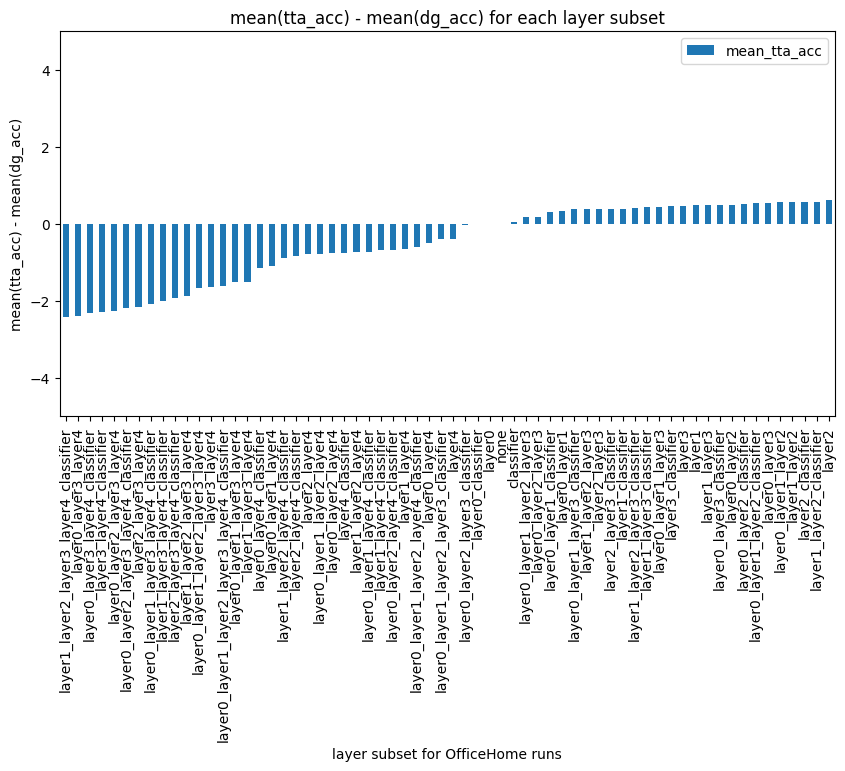

<Figure size 640x480 with 0 Axes>

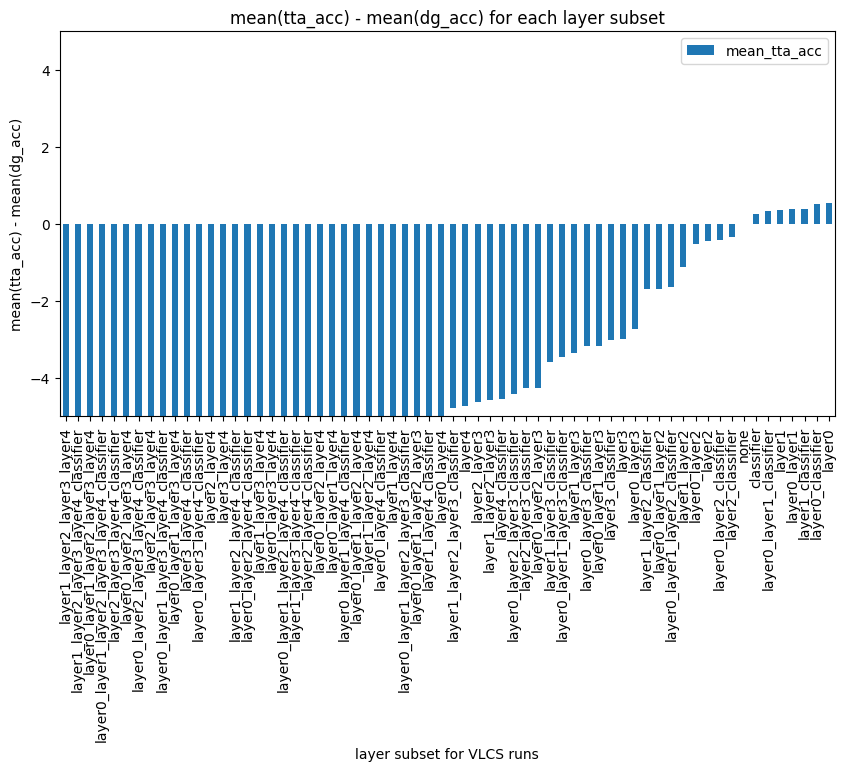

<Figure size 640x480 with 0 Axes>

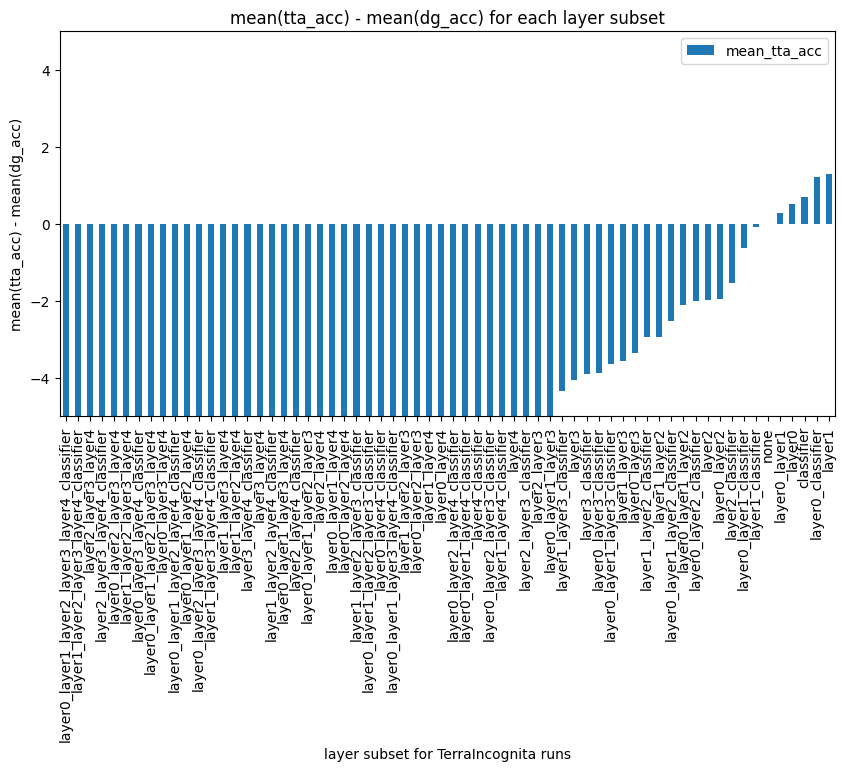

In [52]:
# Plot mean tta_acc for different datasets for different layer subsets
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    plt.figure()
    temp_list = []
    for layer_subset in df_best_hp['find_algo'].unique():
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.sort_values(by=['mean_tta_acc'], ascending=True).set_index('layer_subset').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for '+dataset+' runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))

<Figure size 640x480 with 0 Axes>

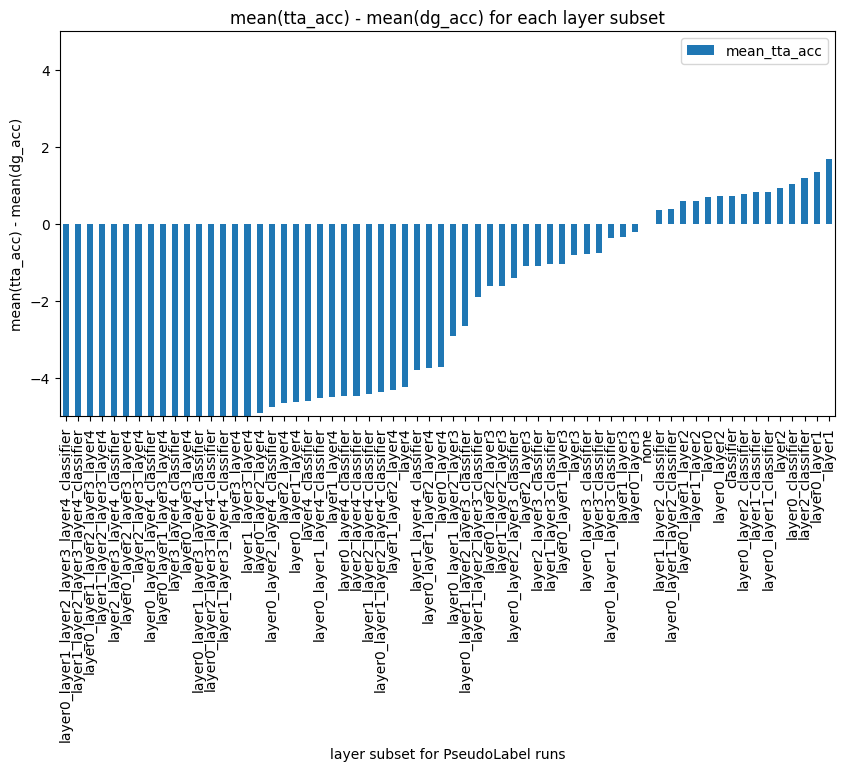

<Figure size 640x480 with 0 Axes>

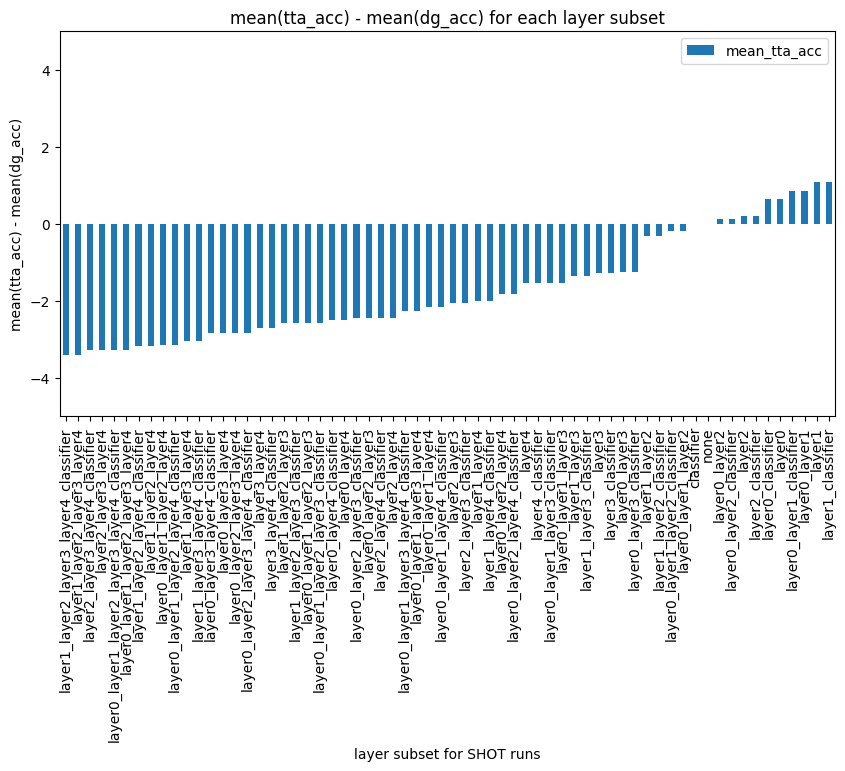

In [53]:
# Plot mean tta_acc for different tta for different layer subsets
for tta in ['PseudoLabel', 'SHOT']:
    plt.figure()
    temp_list = []
    for layer_subset in df_best_hp['find_algo'].unique():
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['tta'] == tta)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.sort_values(by=['mean_tta_acc'], ascending=True).set_index('layer_subset').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for '+tta+' runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))

<Figure size 640x480 with 0 Axes>

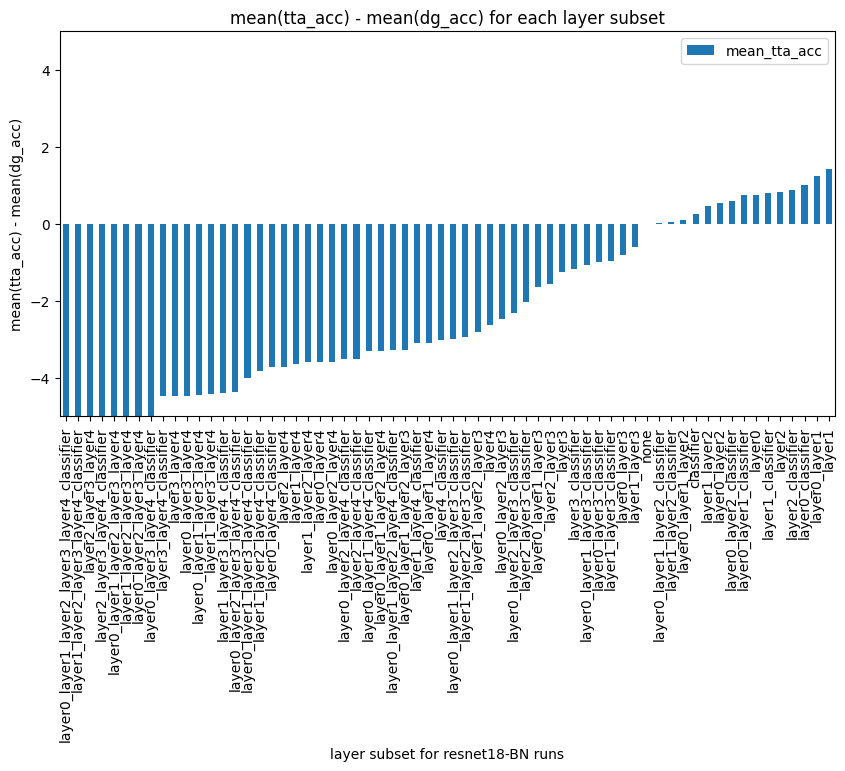

<Figure size 640x480 with 0 Axes>

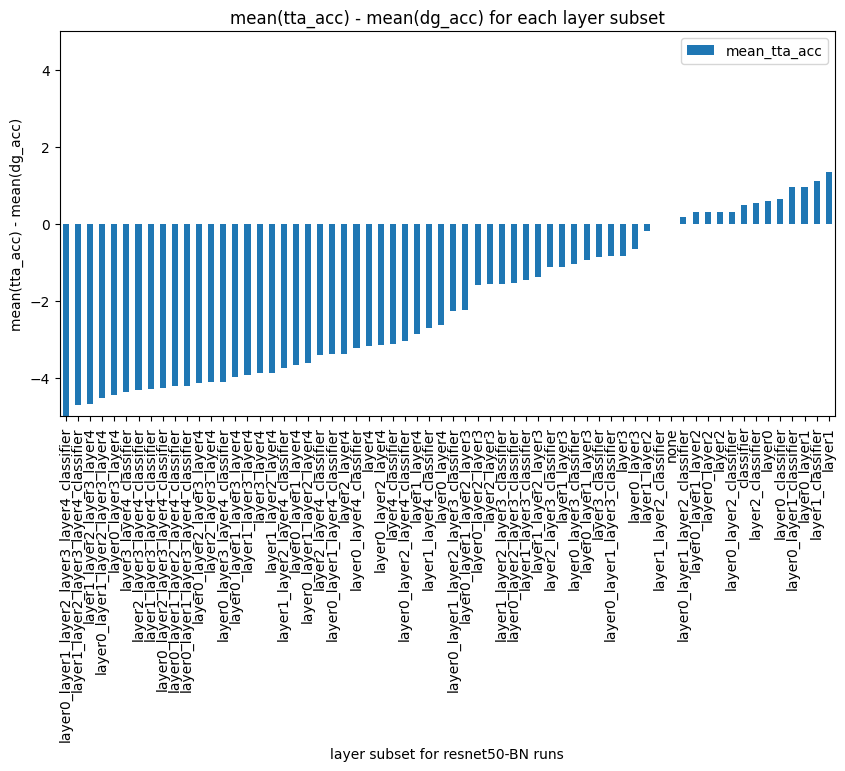

In [54]:
# Plot mean tta_acc for different backbone for different layer subsets
for backbone in ['resnet18-BN', 'resnet50-BN']:
    plt.figure()
    temp_list = []
    for layer_subset in df_best_hp['find_algo'].unique():
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['backbone'] == backbone)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.sort_values(by=['mean_tta_acc'], ascending=True).set_index('layer_subset').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for '+backbone+' runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))

In [55]:
df_best_hp[['find_algo', 'tta_acc>dg']]

,find_algo,tta_acc>dg
0,layer0_layer1_layer2,5.330490
1,layer1_layer2_layer3_classifier,5.223881
2,layer0_layer1_layer2_classifier,4.850746
3,layer1_layer2,4.637527
4,layer2_classifier,4.371002
...,...,...
4091,layer1_classifier,-0.051493
4092,layer0_layer1,-0.102987
4093,layer0_layer1_classifier,-0.102987
4094,layer0,-0.205973


<Axes: title={'center': 'mean(tta_acc - dg_acc) for each layer subset'}, xlabel='layer subset for all runs', ylabel='mean(tta_acc - dg_acc)'>

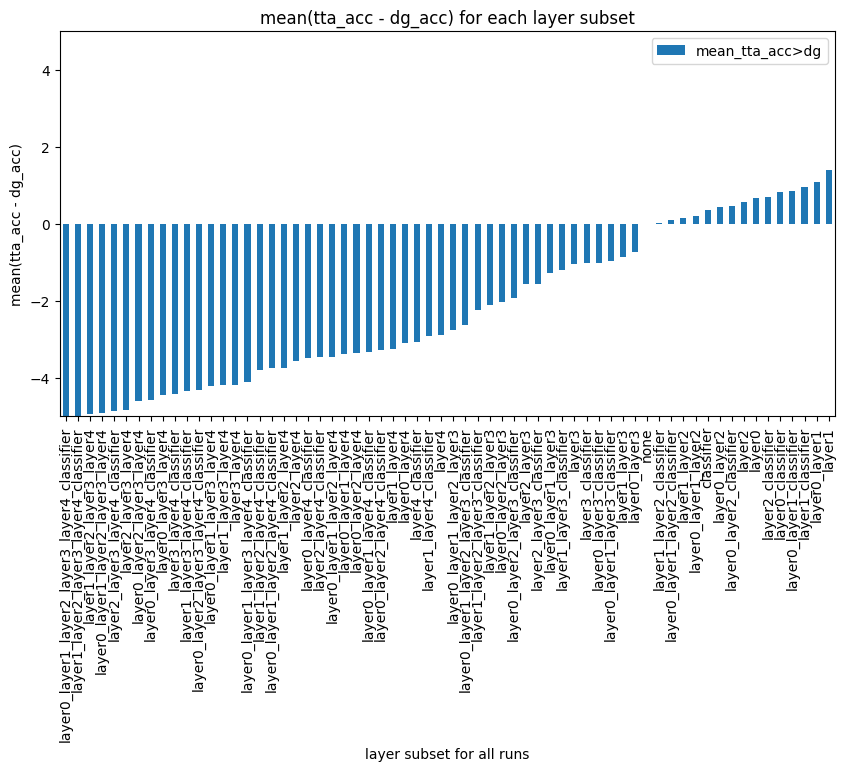

In [56]:
temp_list = []
for layer_subset in df_best_hp['find_algo'].unique():
    temp_dict = {}
    temp_dict['layer_subset'] = layer_subset
    temp_dict['mean_tta_acc>dg'] = df_best_hp[df_best_hp['find_algo'] == layer_subset]['tta_acc>dg'].mean()
    temp_list.append(temp_dict)

df_mean_tta_acc = pd.DataFrame(temp_list)
df_mean_tta_acc.sort_values(by=['mean_tta_acc>dg'], ascending=True).set_index('layer_subset').plot(kind='bar', title='mean(tta_acc - dg_acc) for each layer subset', xlabel='layer subset for all runs', ylabel='mean(tta_acc - dg_acc)', figsize=(10, 5), ylim=(-5, 5))#, color='r')

Plot win count for each layer subset, histogram over all powerset subsets

<Axes: title={'center': 'win count for each layer subset'}, xlabel='layer subset for all runs', ylabel='win count'>

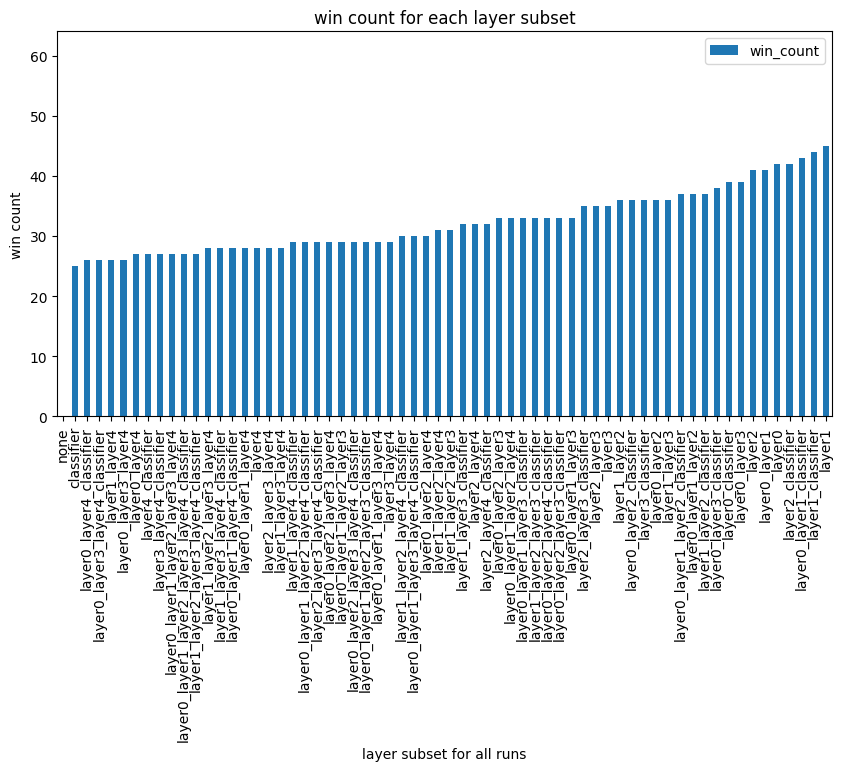

In [57]:
temp_list = []
for layer_subset in df_best_hp['find_algo'].unique():
    temp_dict = {}
    temp_dict['layer_subset'] = layer_subset
    temp_dict['win_count'] = np.sum(df_best_hp[df_best_hp['find_algo'] == layer_subset]['tta_acc>dg'] > 0)# / len(df_best_hp[df_best_hp['find_algo'] == layer_subset]['tta_acc>dg'])
    temp_list.append(temp_dict)

df_win_count = pd.DataFrame(temp_list)
df_win_count.sort_values(by=['win_count'], ascending=True).set_index('layer_subset').plot(kind='bar', title='win count for each layer subset', xlabel='layer subset for all runs', ylabel='win count', figsize=(10, 5), ylim=(0, 64))

Plot mean tta_acc for different single layers

<Figure size 640x480 with 0 Axes>

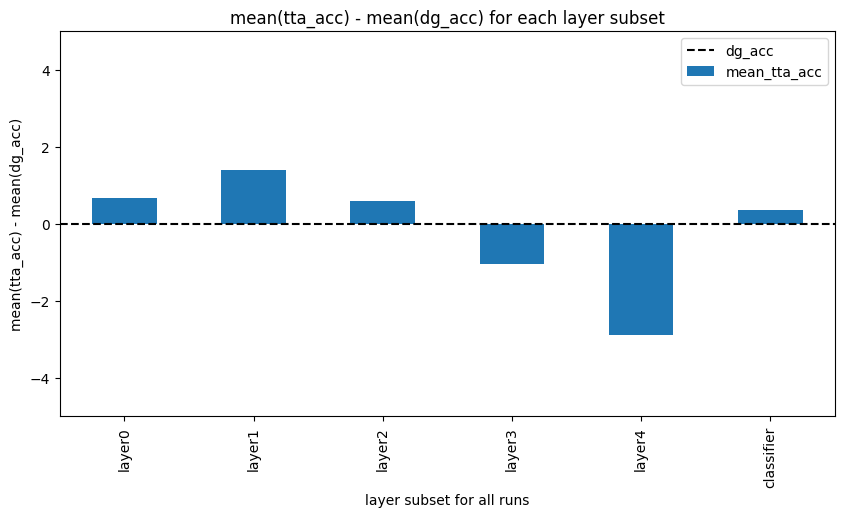

In [58]:
# Plot mean tta_acc for all runs for different layers
plt.figure()
temp_list = []
for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
    temp_dict = {}
    temp_dict['layer_subset'] = layer_subset
    temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset)]['tta_acc'].mean()
    temp_list.append(temp_dict)

df_mean_tta_acc = pd.DataFrame(temp_list)
df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for all runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))
plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
plt.legend()

<Figure size 640x480 with 0 Axes>

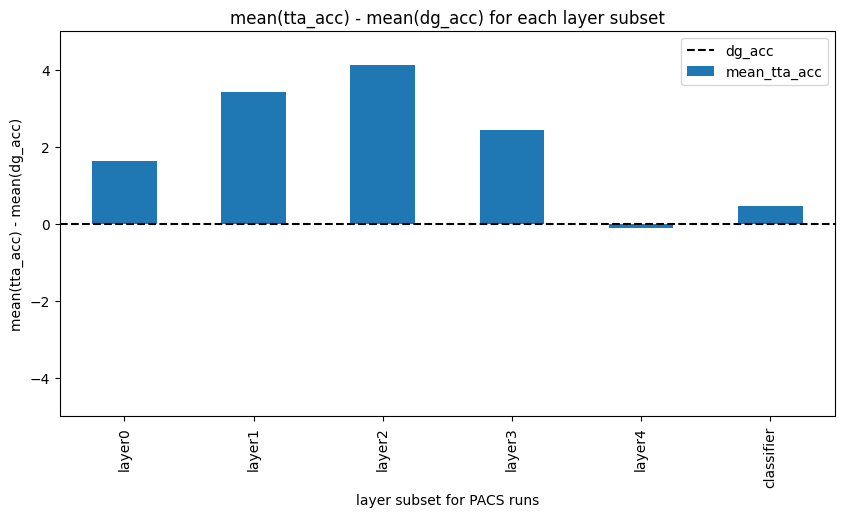

<Figure size 640x480 with 0 Axes>

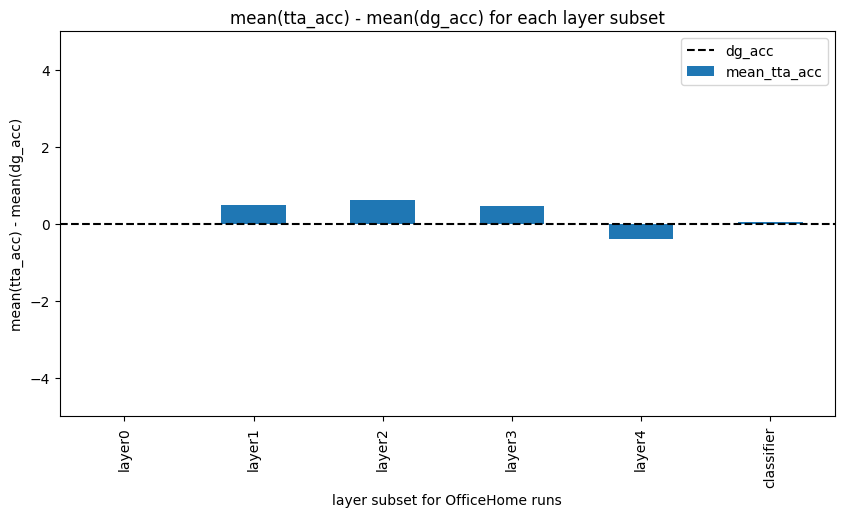

<Figure size 640x480 with 0 Axes>

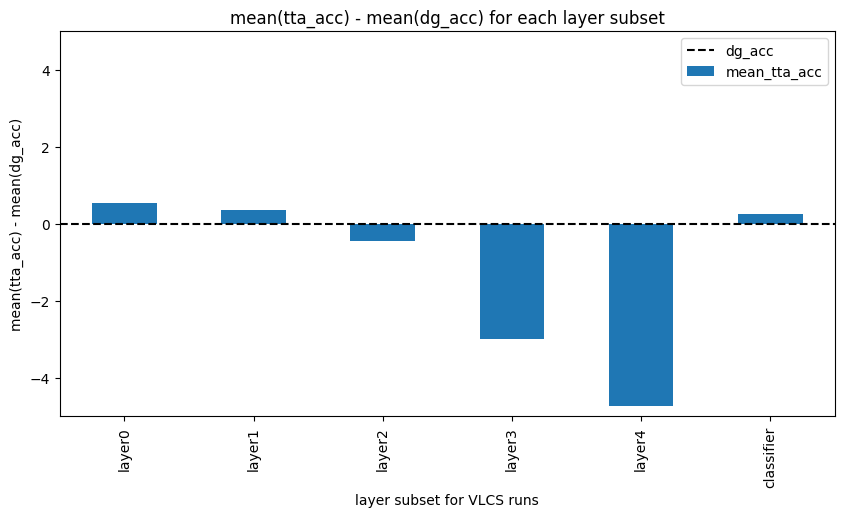

<Figure size 640x480 with 0 Axes>

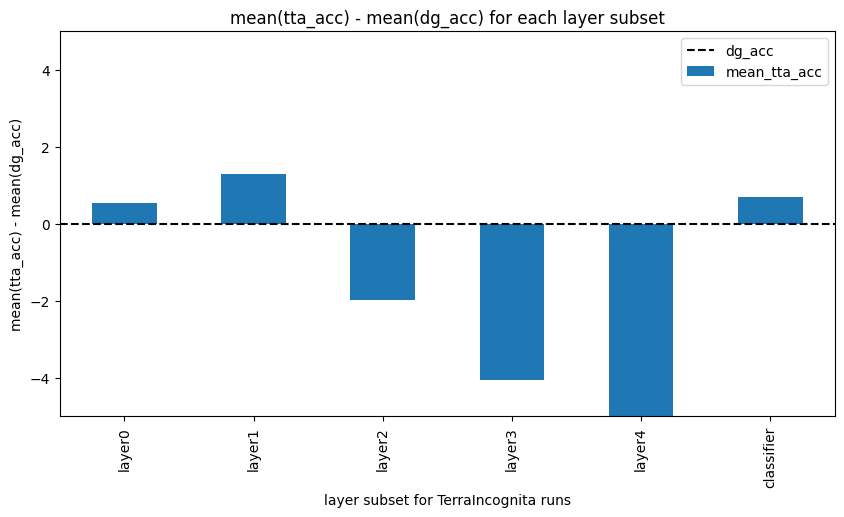

In [59]:
# Plot mean tta_acc for different datasets for different layers
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    plt.figure()
    temp_list = []
    for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for '+dataset+' runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))
    plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
    plt.legend()

<Figure size 640x480 with 0 Axes>

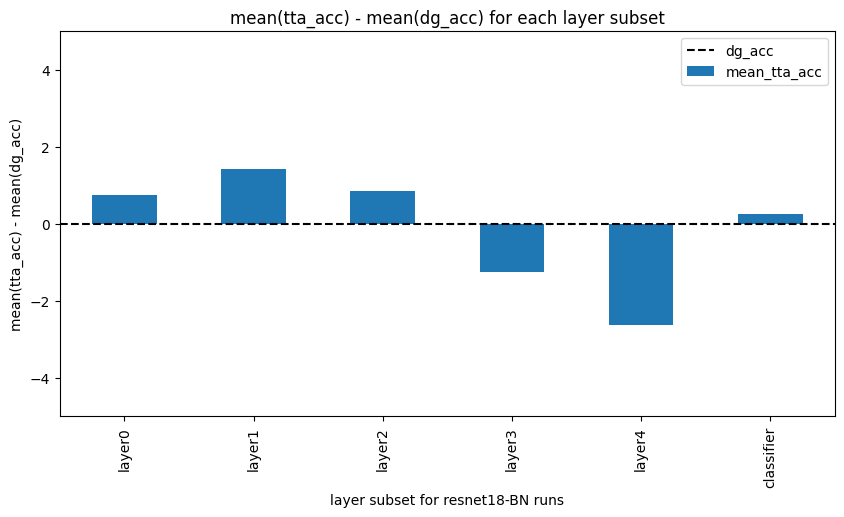

<Figure size 640x480 with 0 Axes>

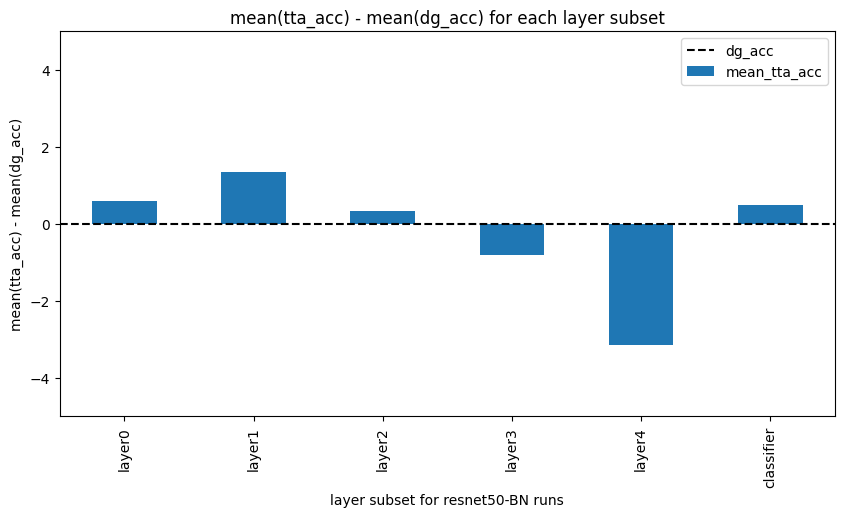

In [60]:
# Plot mean tta_acc for different backbones for different layers
for backbone in ['resnet18-BN', 'resnet50-BN']:
    plt.figure()
    temp_list = []
    for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['backbone'] == backbone)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for '+backbone+' runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))
    plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
    plt.legend()

<Figure size 640x480 with 0 Axes>

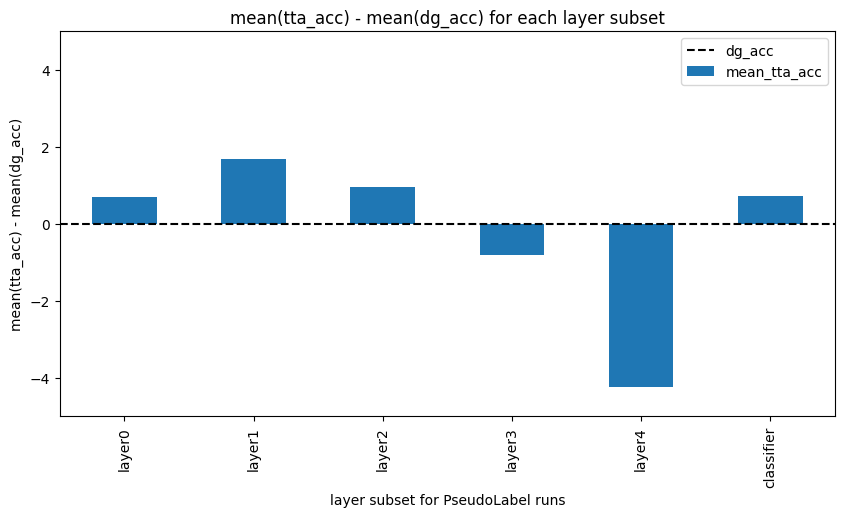

<Figure size 640x480 with 0 Axes>

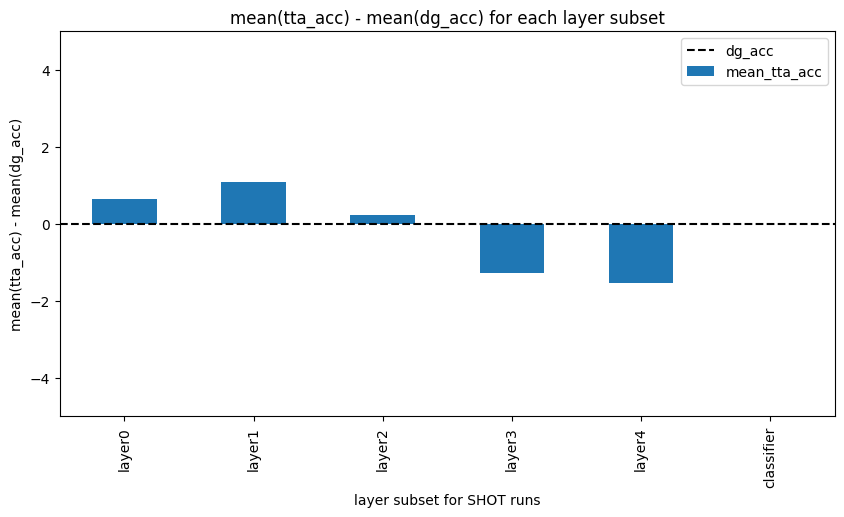

In [61]:
# Plot mean tta_acc for different tta for different layers
for tta in ['PseudoLabel', 'SHOT']:
    plt.figure()
    temp_list = []
    for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['tta'] == tta)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', title='mean(tta_acc) - mean(dg_acc) for each layer subset', xlabel='layer subset for '+tta+' runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5))
    plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
    plt.legend()

Plot mean tta_acc for different single layers and different test_envs

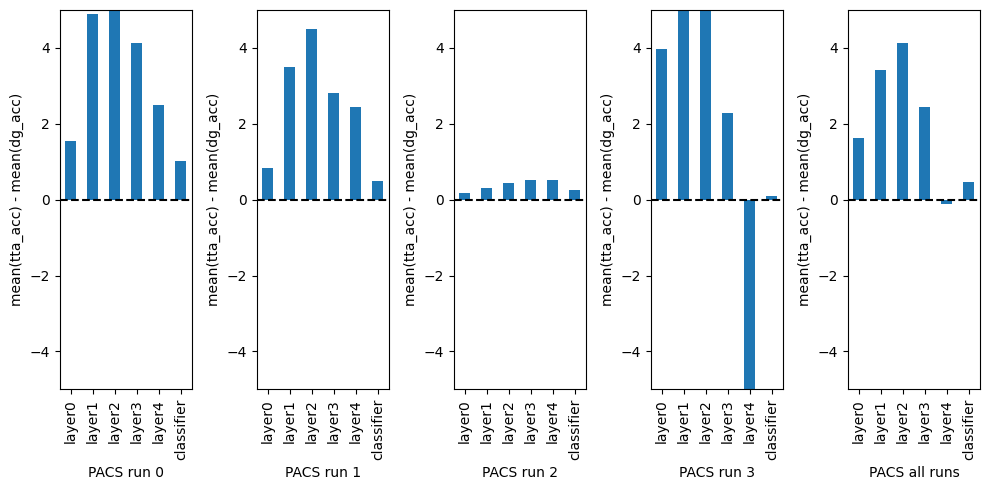

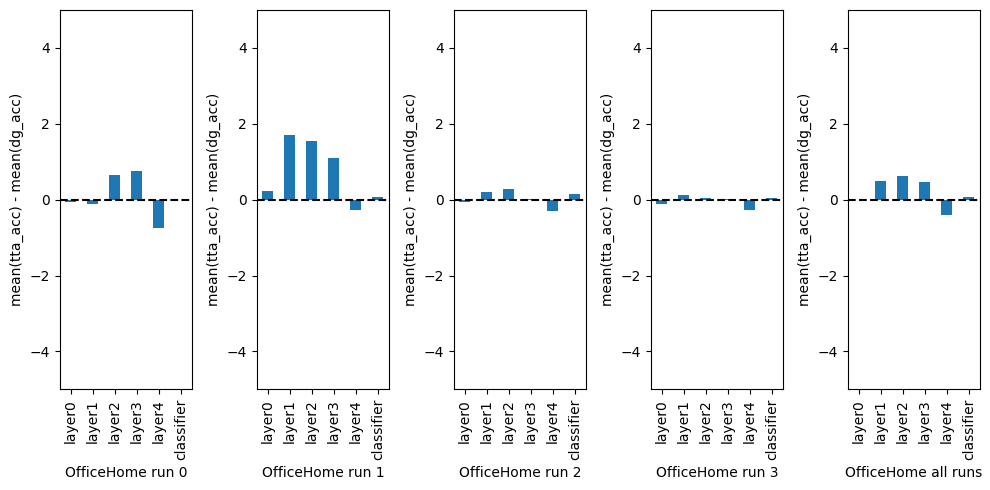

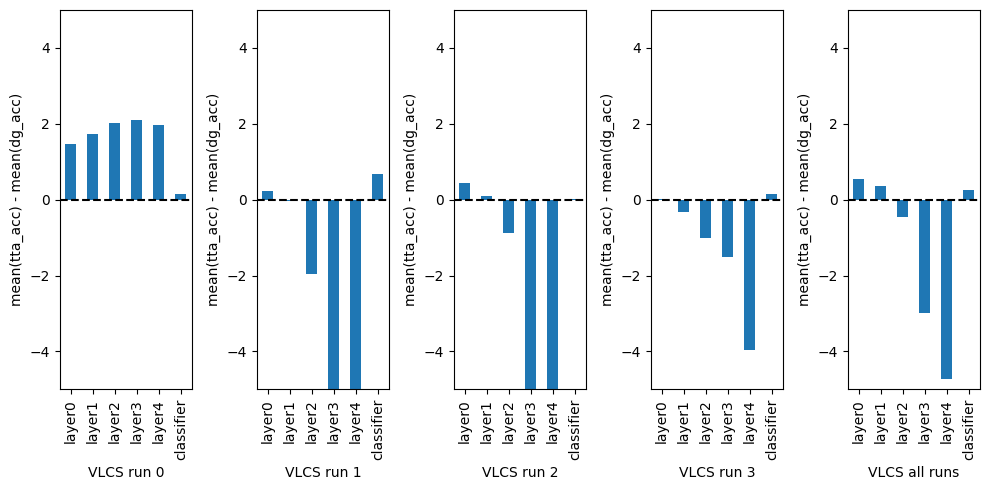

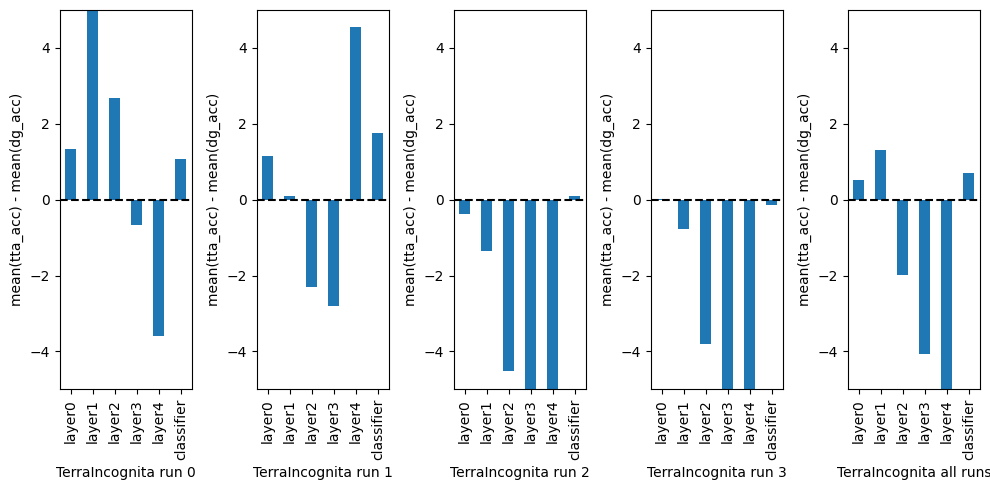

In [62]:
# Plot mean tta_acc for different datasets and different test envs for different layers
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    
    fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(25, 5))
    for test_env in [0, 1, 2, 3]:
        temp_list = []
        for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
            temp_dict = {}
            temp_dict['layer_subset'] = layer_subset
            temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset) & (df_best_hp['test_env'] == test_env)]['tta_acc'].mean()
            temp_list.append(temp_dict)

        df_mean_tta_acc = pd.DataFrame(temp_list)
        df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
        df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', xlabel=dataset+' run '+str(test_env), ylabel='mean(tta_acc) - mean(dg_acc)', ylim=(-5, 5), ax=axes[test_env], legend=False)
        axes[test_env].axhline(y=0, color='k', linestyle='--', label='dg_acc')

    temp_list = []
    for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', xlabel=dataset+' all runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5), ax=axes[test_env+1], legend=False)
    axes[test_env+1].axhline(y=0, color='k', linestyle='--', label='dg_acc')

    plt.tight_layout()

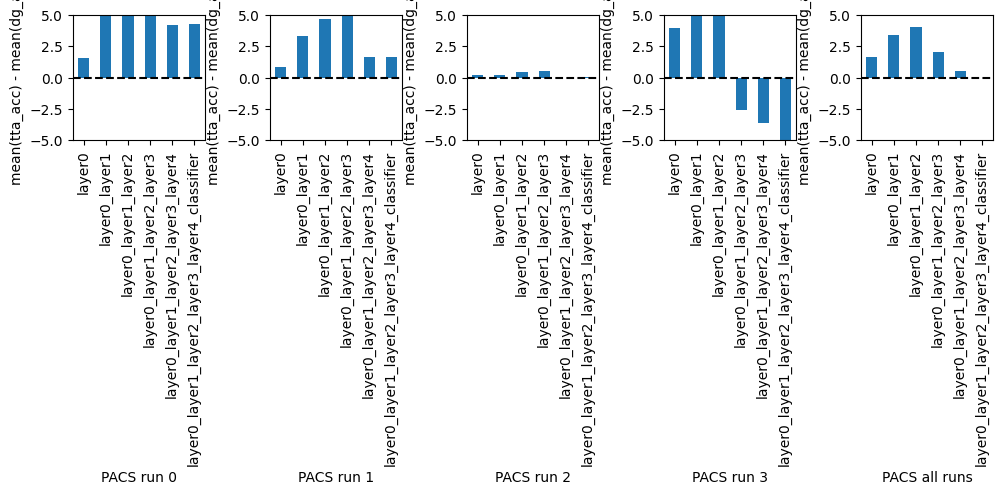

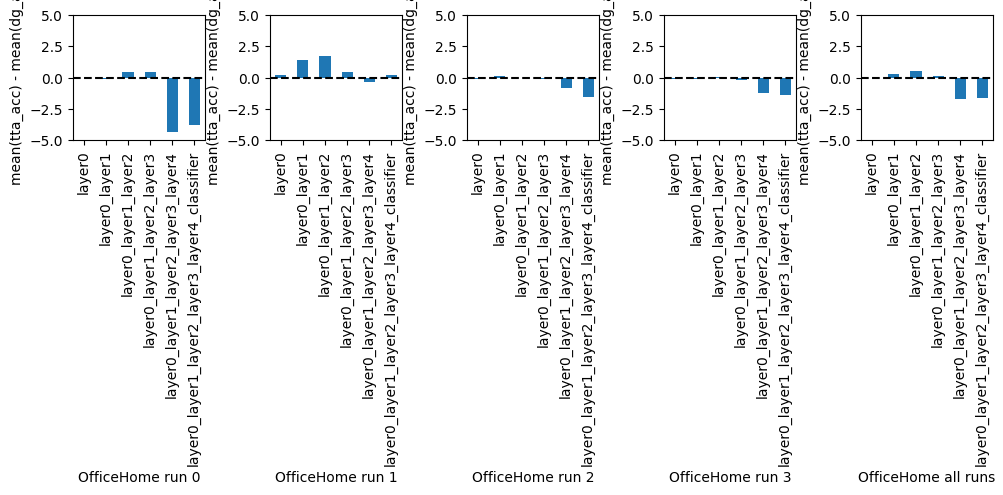

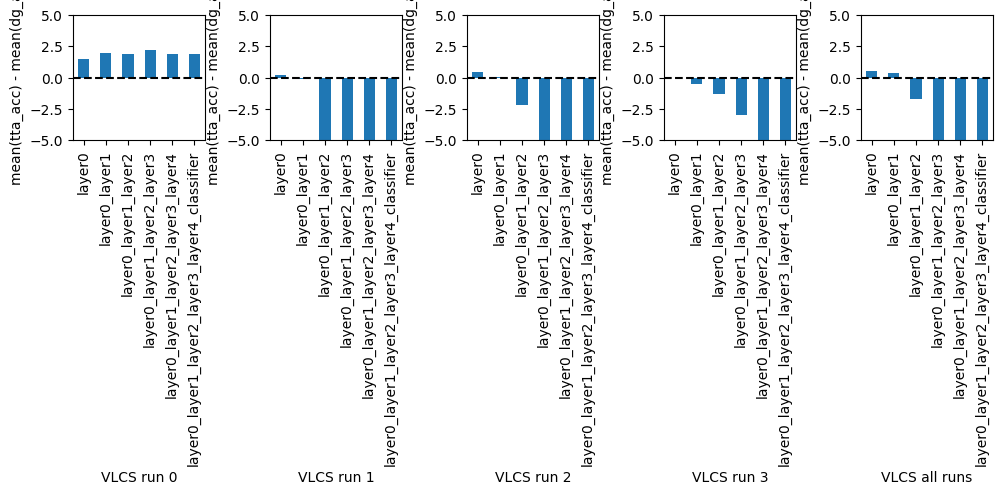

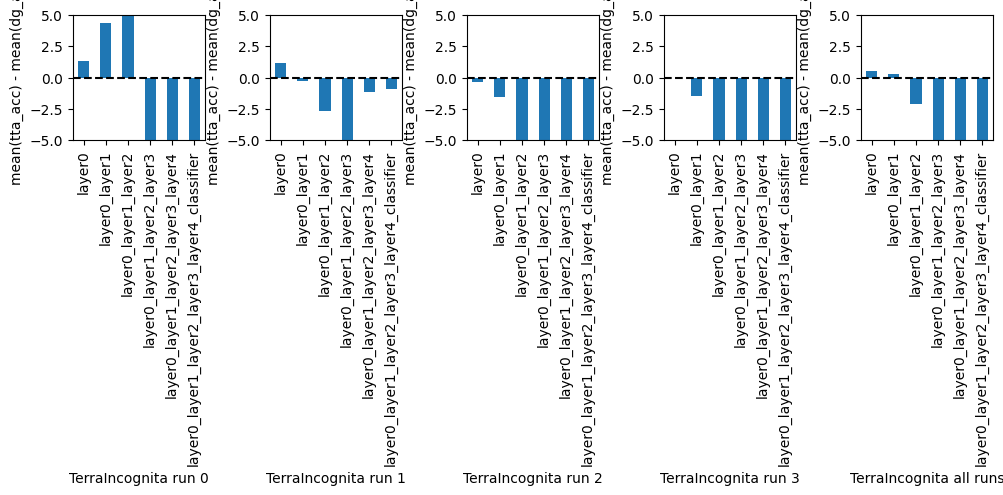

In [63]:
# Plot mean tta_acc for different datasets and different test envs for different layers
for dataset in ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']:
    
    fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(25, 5))
    for test_env in [0, 1, 2, 3]:
        temp_list = []
        for layer_subset in ['layer0', 'layer0_layer1', 'layer0_layer1_layer2', 'layer0_layer1_layer2_layer3', 'layer0_layer1_layer2_layer3_layer4', 'layer0_layer1_layer2_layer3_layer4_classifier', 'none']:
            temp_dict = {}
            temp_dict['layer_subset'] = layer_subset
            temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset) & (df_best_hp['test_env'] == test_env)]['tta_acc'].mean()
            temp_list.append(temp_dict)

        df_mean_tta_acc = pd.DataFrame(temp_list)
        df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
        df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', xlabel=dataset+' run '+str(test_env), ylabel='mean(tta_acc) - mean(dg_acc)', ylim=(-5, 5), ax=axes[test_env], legend=False)
        axes[test_env].axhline(y=0, color='k', linestyle='--', label='dg_acc')

    temp_list = []
    for layer_subset in ['layer0', 'layer0_layer1', 'layer0_layer1_layer2', 'layer0_layer1_layer2_layer3', 'layer0_layer1_layer2_layer3_layer4', 'layer0_layer1_layer2_layer3_layer4_classifier', 'none']:
        temp_dict = {}
        temp_dict['layer_subset'] = layer_subset
        temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset)]['tta_acc'].mean()
        temp_list.append(temp_dict)

    df_mean_tta_acc = pd.DataFrame(temp_list)
    df_mean_tta_acc['mean_tta_acc'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
    df_mean_tta_acc.set_index('layer_subset').drop('none').plot(kind='bar', xlabel=dataset+' all runs', ylabel='mean(tta_acc) - mean(dg_acc)', figsize=(10, 5), ylim=(-5, 5), ax=axes[test_env+1], legend=False)
    axes[test_env+1].axhline(y=0, color='k', linestyle='--', label='dg_acc')

    plt.tight_layout()

Plot to show simulated gradient masks of different Png variants

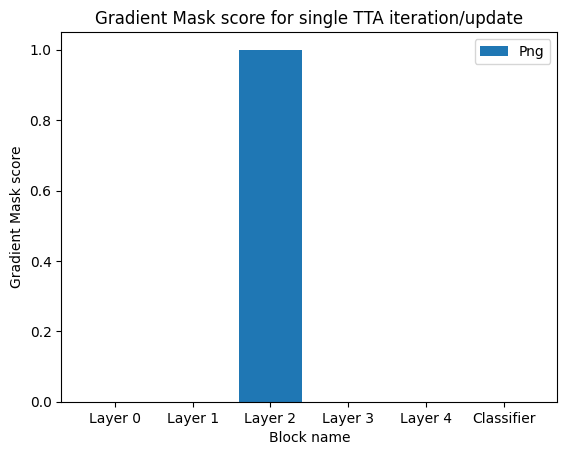

In [64]:
plt.figure()
x_list = ['Layer 0', 'Layer 1', 'Layer 2', 'Layer 3', 'Layer 4', 'Classifier']
y_list = [0, 0, 1, 0, 0, 0]
plt.bar(x_list, y_list, label='Png')
plt.legend()
plt.xlabel('Block name')
plt.ylabel('Gradient Mask score')
plt.title('Gradient Mask score for single TTA iteration/update')
plt.show()

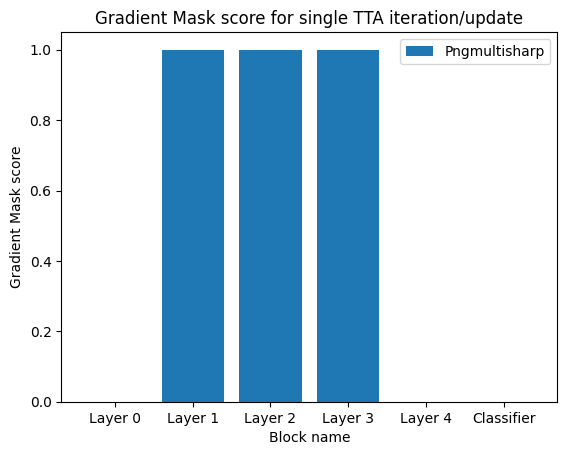

In [65]:
plt.figure()
x_list = ['Layer 0', 'Layer 1', 'Layer 2', 'Layer 3', 'Layer 4', 'Classifier']
y_list = [0, 1, 1, 1, 0, 0]
plt.bar(x_list, y_list, label='Pngmultisharp')
plt.legend()
plt.xlabel('Block name')
plt.ylabel('Gradient Mask score')
plt.title('Gradient Mask score for single TTA iteration/update')
plt.show()

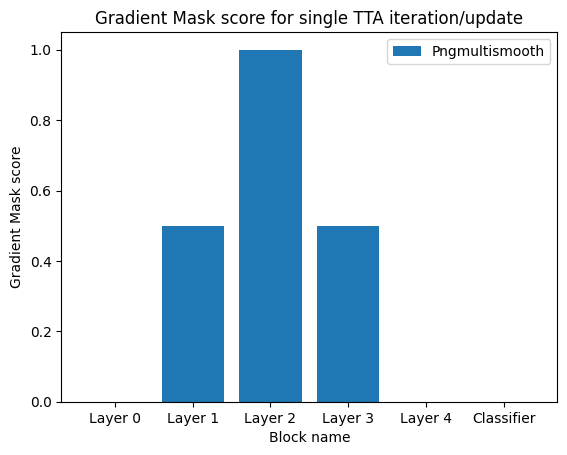

In [66]:
plt.figure()
x_list = ['Layer 0', 'Layer 1', 'Layer 2', 'Layer 3', 'Layer 4', 'Classifier']
y_list = [0, 0.5, 1, 0.5, 0, 0]
plt.bar(x_list, y_list, label='Pngmultismooth')
plt.legend()
plt.xlabel('Block name')
plt.ylabel('Gradient Mask score')
plt.title('Gradient Mask score for single TTA iteration/update')
plt.show()

Plot tta_acc - dg_acc vs block id for a given dataset, test_env, backbone and tta

<Figure size 1000x500 with 0 Axes>

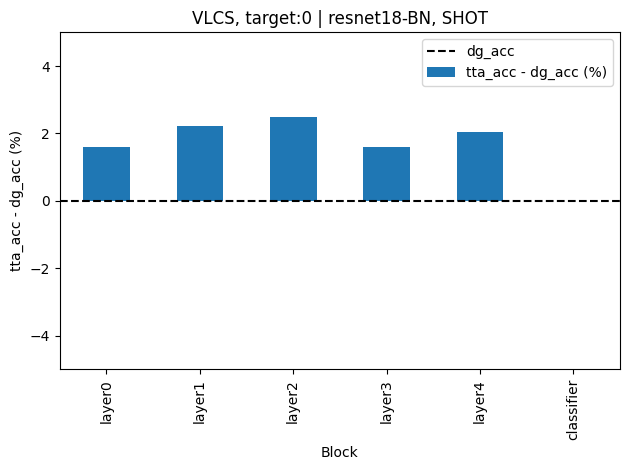

<Figure size 1000x500 with 0 Axes>

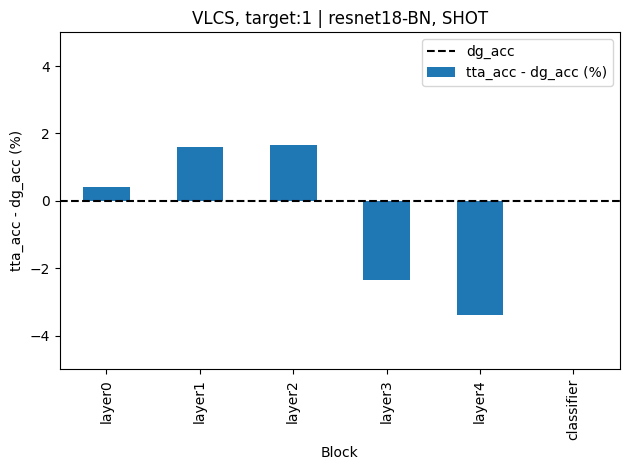

<Figure size 1000x500 with 0 Axes>

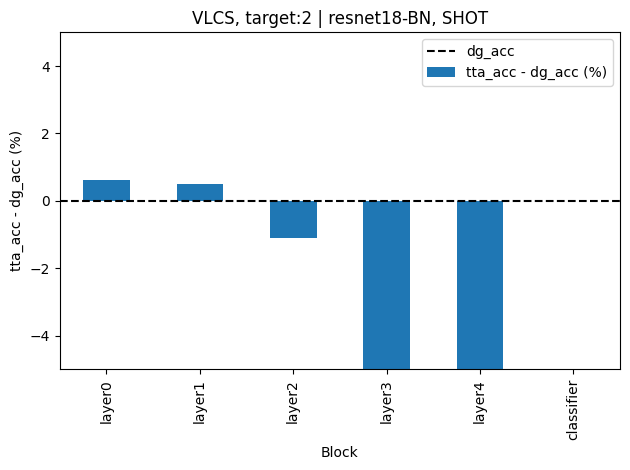

<Figure size 1000x500 with 0 Axes>

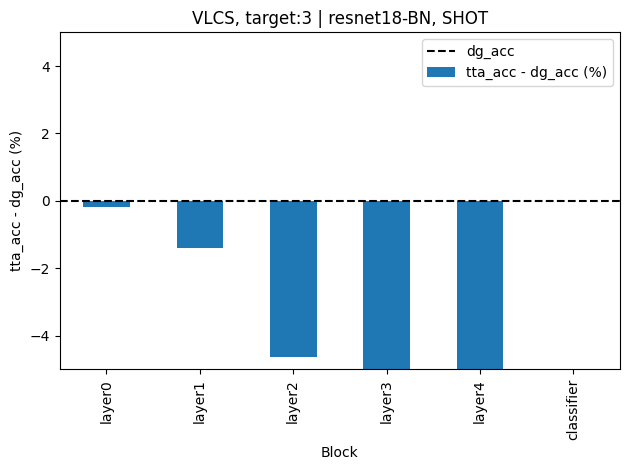

In [73]:
# Plot mean tta_acc for different datasets and different test envs for different layers
# dataset_list = ['PACS', 'OfficeHome', 'VLCS', 'TerraIncognita']
# backbone_list = ['resnet18-BN', 'resnet50-BN']
# tta_list = ['PseudoLabel', 'SHOT']
dataset_list = ['VLCS']
backbone_list = ['resnet18-BN']
tta_list = ['SHOT']
for dataset in dataset_list:
    for backbone in backbone_list:
        for tta in tta_list:
            for test_env in [0, 1, 2, 3]:
                plt.figure(figsize=(10, 5))
                temp_list = []
                for layer_subset in ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier', 'none']:
                    temp_dict = {}
                    temp_dict['layer_subset'] = layer_subset
                    temp_dict['mean_tta_acc'] = df_best_hp[(df_best_hp['find_algo'] == layer_subset) & (df_best_hp['dataset'] == dataset) & (df_best_hp['test_env'] == test_env) & (df_best_hp['backbone'] == backbone) & (df_best_hp['tta'] == tta)]['tta_acc'].mean()
                    temp_list.append(temp_dict)

                df_mean_tta_acc = pd.DataFrame(temp_list)
                df_mean_tta_acc['tta_acc - dg_acc (%)'] = df_mean_tta_acc['mean_tta_acc'] - df_mean_tta_acc[df_mean_tta_acc['layer_subset'] == 'none']['mean_tta_acc'].values[0]
                df_mean_tta_acc.drop(columns=['mean_tta_acc']).set_index('layer_subset').drop('none').plot(kind='bar', xlabel='Block', ylabel='tta_acc - dg_acc (%)', ylim=(-5, 5), legend=False)
                # df_mean_tta_acc.drop(columns=['mean_tta_acc']).set_index('layer_subset').drop('none').plot(kind='bar', xlabel='Block', ylabel='tta_acc - dg_acc (%)', legend=False)
                plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
                plt.legend()
                plt.title(dataset+', target:'+str(test_env)+' | '+backbone+', '+tta)
                plt.tight_layout()